# Novel Hypothesis: The Impact of Semantic Similarity and Word Category on Neural Encoding and Predictive Error.

## Overview

The general consensus is that the brain does not represent all words in the same way. The brain uses distributed semantic representations, which change depending on the context but also depending on what the specifc word is. Base on this knowledge, the notebook tests how the encoding models are influenced by the words used, specifically two sub-questions/hypothesis are tested :


### Hypothesis 1 — How the Word Category Modulates Encoding (extension of Fig 6B )
Original paper averaged glove and gpt embeddings across all words, I hypothesise the encoding results (correlation) can differ by **lexical category**:
- **Lexical/content words** (nouns, verbs, adjectives, adverbs) vs **functional words** (determiners, prepositions, conjunctions)
- **Nouns** (eople, places or things) vs **verbs** ( sleep, run, dance, sing); most nouns and verbs are lexical
- **Concrete** (things you can perceive or sense e.g. apple, chair, rain) vs **abstract** (hings that are abstract/can’t directly sense like truth, freedom,justice) words


### Hypothesis 2 — How semantic distance between Prediction and true word for the incorrect words, modulates prediction-error signals (extension of Fig 4B )
The original paper grouped together all incorrect predictions, in this notebook, I separate the incorrect words into 3 groups based on the distance:
- **Group 1 (nearby)** : incorrectly predicted word is close to true word
- **Group 2(further-away)**: incorrectly predicted word is further award from true word
- **Group 3(Far away)**: incorrectly predicted word is far from true word

Distance is measured by GloVe cosine distance between the *predicted* word and the *actually perceived* words. Can't use GPT contextual embedding since only have words that are actually present in the sequence/ do not have incorrect prediction's embedding. 

Electrodes used: same as before 174 (from the significant electrodes analysis)


# Setup (similar methods as other notebooks)

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import mne
import os
import re
import nltk
import warnings
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import h5py
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd
import gc

from mne_bids import BIDSPath
from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import fdrcorrection
from transformers import GPT2Tokenizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import fdrcorrection


# Download NLTK resources
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from nltk import pos_tag
from nltk.corpus import wordnet as wn

warnings.filterwarnings('ignore')
mne.set_log_level('WARNING')

print("All imports successful.")

/opt/anaconda3/envs/aineuro/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All imports successful.


In [ ]:
# path were data is
bids_root = "add path where your BIDS dataset is stored"  

# Subject list (sub-01 excluded in earlier analysis (see the first notebook: Electrode Selection and figure 4 A)
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]

# Lags: 161 points from -2000 ms to +2000 ms in 25 ms steps ->Smoothing
lags_ms = np.linspace(-2000, 2000, 161)

# were the results get stored
RESULTS_DIR_A1 = "results_novel_a1_categories"
RESULTS_DIR_A2 = "results_novel_a2_semdist"
os.makedirs(RESULTS_DIR_A1, exist_ok=True)
os.makedirs(RESULTS_DIR_A2, exist_ok=True)

print(f"bids_root     : {bids_root}")
print(f"Results dir 1 : {RESULTS_DIR_A1}")
print(f"Results dir 2 : {RESULTS_DIR_A2}")

bids_root     : /Users/iadician/Desktop/AI NEURO CODE/
Results dir 1 : results_novel_a1_categories
Results dir 2 : results_novel_a2_semdist


## 2. Data Loading 

In [3]:
# Load transcript 
transcript_path = "stimuli/podcast_transcript.csv"
df = pd.read_csv(transcript_path)

# Load GloVe 50-d embeddings 
glove_path = 'glove.6B.50d.txt'

def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")
    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            values = line.split()
            word   = values[0]
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector
    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict

glove_model = load_glove_to_dict(glove_path)

# Clean word 
def clean_word(w):
    w = str(w).lower()
    w = re.sub(r"['''\'ʻ]", "'", w)
    return w.strip(" .,!?;:\"()-[]")

EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm', 'uh', 'um'}

df["word_clean"] = df["word"].apply(clean_word)

def get_glove_vector(w):
    if w in EXCLUDE_FILLERS or w not in glove_model:
        return None
    return glove_model[w]

df["glove_embedding"] = df["word_clean"].apply(get_glove_vector)
df_glove = df.dropna(subset=["glove_embedding"]).copy()
print(f"Words with GloVe embedding: {len(df_glove)} / {len(df)}")

Loading glove.6B.50d.txt...
Done! 400000 words loaded.
Words with GloVe embedding: 4867 / 5136


In [4]:
df_glove.shape

(4867, 5)

In [5]:
df_glove.head(3)

,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."


# Hypothesis 1: Word Category

## Baseline analysis for hypothesis 1

In [6]:
transcript_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_path, sep="\t", index_col=0)


In [7]:
df_gpt.shape

(5491, 10)

In [8]:
embedding_path = "stimuli/gpt2-xl/features.hdf5"
modelname, layer = 'gpt2-xl', 48
with h5py.File(embedding_path, "r") as f:
    contextual_embeddings = f[f"layer-{layer}"][...]
print(f"LLM embedding matrix has shape: {contextual_embeddings.shape}")

LLM embedding matrix has shape: (5491, 1600)


In [9]:
# 1. PCA: Reduce from 1600 to 50 dimensions

pca = PCA(n_components=50)
embeddings_50d = pca.fit_transform(contextual_embeddings)
print(f"Reduced embedding shape: {embeddings_50d.shape}") # (5491, 50)

# 2. Group by word_idx and average the 50-d embeddings

aligned_embeddings_50d = []
for _, group in df_gpt.groupby("word_idx"):
    indices = group.index.to_numpy()
    average_emb = embeddings_50d[indices].mean(0) 
    aligned_embeddings_50d.append(average_emb)

aligned_embeddings_50d = np.stack(aligned_embeddings_50d)
print(f"Final word-level embedding matrix shape: {aligned_embeddings_50d.shape}") # (5136, 50)

# 3. Create a word-level DataFrame

df_words = df_gpt.groupby("word_idx").first().reset_index()

# 4. Insert the 50-d embeddings into the new DataFrame
df_words["gpt_embedding_50d"] = list(aligned_embeddings_50d)

print(f"df_words shape: {df_words.shape}")
df_words.head()

Reduced embedding shape: (5491, 50)
Final word-level embedding matrix shape: (5136, 50)
df_words shape: (5136, 11)


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9688848, -2.7204232, -2.0838425, -4.468509..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27876085, -0.85267466, -2.1737204, 0.67496..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3147047, -3.9556947, 1.9342884, ..."
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,"[-6.756072, 2.8778949, 4.2936225, -1.2895249, ..."
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,"[-6.889707, 5.5559106, -1.247399, 5.0973363, 6..."


In [10]:
# Apply cleaning
df_words["word_clean"] = df_words["word"].apply(clean_word)

#Exclude fillers 
mask = df_words["word_clean"].apply(
    lambda w: w not in EXCLUDE_FILLERS and w in glove_model
)

# Apply the mask to create your final filtered dataframe
df_gpt_final = df_words[mask].copy()


# Verification
print(f"Initial Word-Level rows : {len(df_words)}")
print(f"Final aligned rows      : {len(df_gpt_final)}")
print(f"Rows dropped            : {len(df_words) - len(df_gpt_final)}")

df_gpt_final.head(3)

Initial Word-Level rows : 5136
Final aligned rows      : 4867
Rows dropped            : 269


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9688848, -2.7204232, -2.0838425, -4.468509...",act
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27876085, -0.85267466, -2.1737204, 0.67496...",one
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3147047, -3.9556947, 1.9342884, ...",monkey


In [11]:
#Getting the embeddings for Glove and for GPT
#In figure 6 a) of the paper the authors selected only the words that occured at least 5 times in the transcript to do the "scrambled context" and "average context" control conditions
#Here, we do not need two those two control conditions:
##1)Because this is not the focus on the experiment
##2)because using the full set (glove and gpt embeddings) gives a larger and more diverse vocbulary, if I filtered, might end up with only "non-functional words" as they tend to repeat more than rare nouns that can appear only once

##### Glove:
X_glove = np.stack(df_glove['glove_embedding'].values).astype("float32") 
print(f"Shape of X_glove: {X_glove.shape}")

#### GPT:
X_gpt = np.stack(df_gpt_final['gpt_embedding_50d'].values).astype("float32")
print(f"Shape of X_gpt: {X_gpt.shape}")


Shape of X_glove: (4867, 50)
Shape of X_gpt: (4867, 50)


In [ ]:
# Current folder directory
bids_root = "Add path where your BIDS dataset is stored"

**Baseline plot:**
First we need the baseline plot since figure 6b has only the words with 5 or more repitions for gpt embedding. Below we plot glove and gpt embedding for the 4867 words.

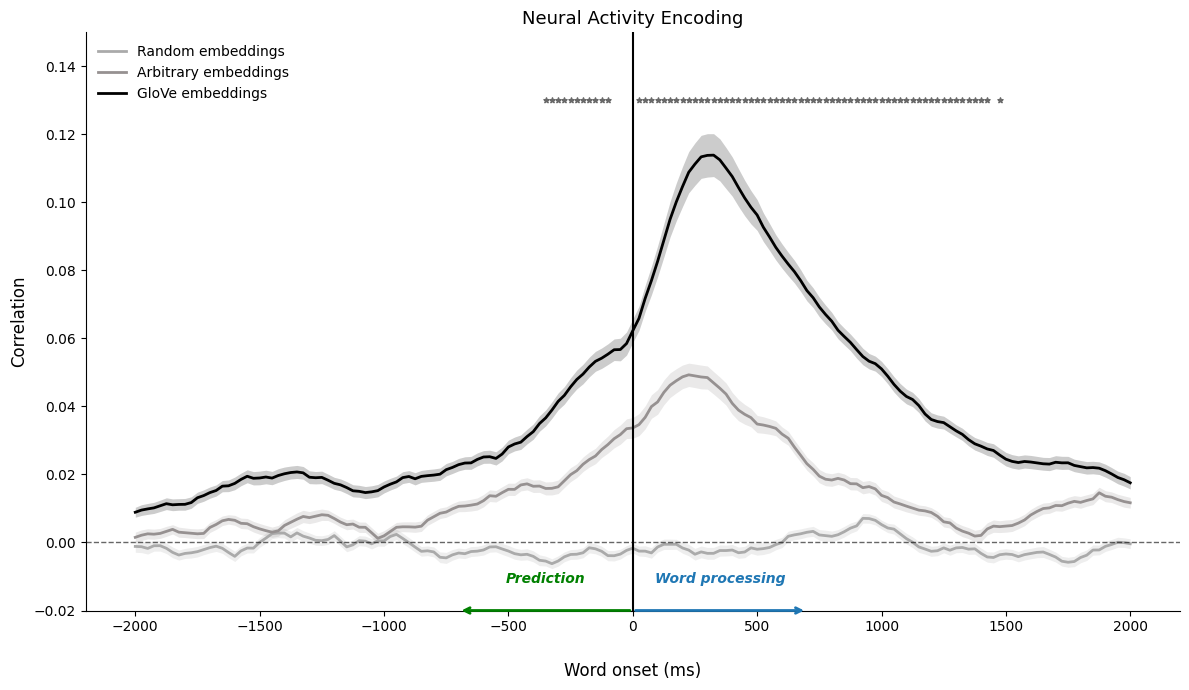

In [13]:
# since we already ran the encoding for Glove, arbitary and random, we can just load those correlations and plot them

lags_ms = np.linspace(-2000, 2000, 161)
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]

# Load electrode list
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

r_glove_list, r_arb_list, r_rand_list, r_gpt_list = [], [], [], []

# 2) Load the saved data
for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0: continue
    sig_idx = sub_sig["elec_idx"].values
    try:
        g = np.load(f"corerlations_all{sid}.npy")[:, sig_idx, :].mean(axis=0)
        a = np.load(f"corrs_arb_{sid}.npy").mean(axis=0)
        r = np.load(f"corrs_rand_{sid}.npy").mean(axis=0)
        
        r_glove_list.append(g)
        r_arb_list.append(a)
        r_rand_list.append(r)
        
        
    except FileNotFoundError:
        print(f"sub-{sid} files not found, skipping")

# Concatenate results
r_glove = np.concatenate(r_glove_list, axis=0)
r_arb   = np.concatenate(r_arb_list,   axis=0)
r_rand  = np.concatenate(r_rand_list,  axis=0)
N_elec  = r_glove.shape[0]

# 3) Permutation Test
diff = r_glove - r_arb
actual_mean = diff.mean(axis=0)
pct_pos = (diff > 0).mean(axis=0)

N_PERMS = 5000
rng = np.random.default_rng(seed=0)
signs_per_elec = rng.choice(np.array([-1, 1], dtype=np.float32), size=(N_PERMS, N_elec, 1))
null_dist = (signs_per_elec * diff[np.newaxis, :, :]).mean(axis=1)

p_vals = np.array([(null_dist[:, t] >= actual_mean[t]).mean() for t in range(len(lags_ms))])
sig_fdr, _ = fdrcorrection(p_vals, alpha=0.01)
sig_final = sig_fdr & (pct_pos >= 0.76)

# 4) Plotting Function
def make_plot(sig_lags):
    mean_glove = r_glove.mean(axis=0); se_glove = r_glove.std(axis=0) / np.sqrt(N_elec)
    mean_arb   = r_arb.mean(axis=0);   se_arb   = r_arb.std(axis=0)   / np.sqrt(N_elec)
    mean_rand  = r_rand.mean(axis=0);  se_rand  = r_rand.std(axis=0)  / np.sqrt(N_elec)

    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plotting Lines and Shading
    colors = [("#aaaaaa", mean_rand, se_rand, "Random"), 
              ("#969191", mean_arb, se_arb, "Arbitrary"), 
              ("black", mean_glove, se_glove, "GloVe")]

    for col, m, s, lab in colors:
        ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.2, linewidth=0)
        ax.plot(lags_ms, m, color=col, linewidth=2, label=f"{lab} embeddings")

    if sig_lags.any():
        ax.scatter(lags_ms[sig_lags], np.full(sig_lags.sum(), 0.13),
                    marker="*", s=15, color="dimgrey", zorder=10)

    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6)
    ax.set_ylim(-0.02, 0.15)
    ax.spines['bottom'].set_position(('data', -0.02))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Arrows
    ax.annotate('', xy=(-700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='green', lw=2))
    ax.annotate('', xy=(700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=2))

    ax.text(-350, -0.012, "Prediction", color="green", style="italic", ha="center", fontweight='bold')
    ax.text(350, -0.012, "Word processing", color="#1f77b4", style="italic", ha="center", fontweight='bold')

    ax.axvline(0, color="black", lw=1.5)
    ax.set_xlabel("Word onset (ms)", fontsize=12, labelpad=20)
    ax.set_ylabel("Correlation", fontsize=12)
    ax.set_title("Neural Activity Encoding" , fontsize=13)

    plt.legend(loc="upper left", frameon=False)
    plt.tight_layout()
    plt.show()

make_plot(sig_final)

In [18]:
#But we need to run the encoding model for gpt embedding, save it, and plot that (Add that line to the previous plot above)
#Since we only ran gpt embedding for figure 6b which had only the words that were 5 or more, here this has all the words included in glove embedding:

sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)
alphas      = np.logspace(1, 10, 10)
inner_cv    = KFold(n_splits=5, shuffle=False)
model       = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)

def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)

all_corrs_gpt = []

for sid in subject_ids:

    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values
    print(f"\nsub-{sid}: {len(sig_indices)} significant electrodes → {sig_indices}")

    # Load raw and pick left-hemisphere significant electrodes (identical pipeline)
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    lh_ch_names = [ch for ch, keep in zip(raw.ch_names, lh_mask) if keep]
    raw = raw.copy().pick(lh_ch_names)

    sig_ch_names = [raw.ch_names[i] for i in sig_indices]
    raw = raw.copy().pick(sig_ch_names)
    print(f"  raw now has {len(raw.ch_names)} channels (significant only)")

    # Build epochs
    sfreq  = raw.info['sfreq']
    events = np.zeros((len(df_glove), 3), dtype=int)
    events[:, 0] = (df_glove['start'].values * sfreq).astype(int)

    epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                        baseline=None, proj=False, event_id=None,
                        preload=True, event_repeated="merge")

    # Window averaging / smoothing → (n_words, n_sig_elec, 161)
    times       = epochs.times
    lag_centers = np.arange(-2.0, 2.0 + 0.025/2, 0.025)
    WIN_HALF    = 0.100
    lag_masks   = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                   for τ in lag_centers]

    epochs_data            = epochs.get_data(copy=True)
    n_words, n_sig_elec, _ = epochs_data.shape
    epochs_shape           = (n_sig_elec, 161)

    epochs_windowed = np.stack(
        [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
    ).astype(np.float32)

    Y = epochs_windowed.reshape(n_words, n_sig_elec * 161)
    if "torch" in get_backend().__name__:
        Y = Y.astype(np.float32)

    # Align GPT embeddings to the epochs that were actually kept
    X_gpt_sel = X_gpt[epochs.selection].astype("float32")

    print(f"  Running GPT embeddings...")
    corrs_gpt = train_encoding(X_gpt_sel, Y, epochs_shape)
    np.save(f"corrs_gpt_{sid}.npy", corrs_gpt)
    print(f"  Saved corrs_gpt_{sid}.npy  shape: {corrs_gpt.shape}")
    all_corrs_gpt.append(corrs_gpt)

print("\nDone. All GPT correlation files saved.")

sub-02: no significant electrodes, skipping

sub-03: 41 significant electrodes → [  2   5   8   9  17  25  34  35  36  42  44  45  69  72  73  74  76  77
  78  80  84  85  86  94 106 110 111 112 113 114 115 117 118 119 120 121
 122 124 153 155 178]
  raw now has 41 channels (significant only)
  Running GPT embeddings...
  Saved corrs_gpt_03.npy  shape: (10, 41, 161)

sub-04: 15 significant electrodes → [13 21 23 29 30 32 33 34 43 60 61 72 73 74 75]
  raw now has 15 channels (significant only)
  Running GPT embeddings...
  Saved corrs_gpt_04.npy  shape: (10, 15, 161)

sub-05: 3 significant electrodes → [21 41 42]
  raw now has 3 channels (significant only)
  Running GPT embeddings...
  Saved corrs_gpt_05.npy  shape: (10, 3, 161)

sub-06: 25 significant electrodes → [  5  14  20  21  22  28  32  41  50  52  57  58  59  61  62  73  98  99
 100 106 107 109 115 116 121]
  raw now has 25 channels (significant only)
  Running GPT embeddings...
  Saved corrs_gpt_06.npy  shape: (10, 25, 161)

s

Loaded 174 significant electrodes across all subjects.


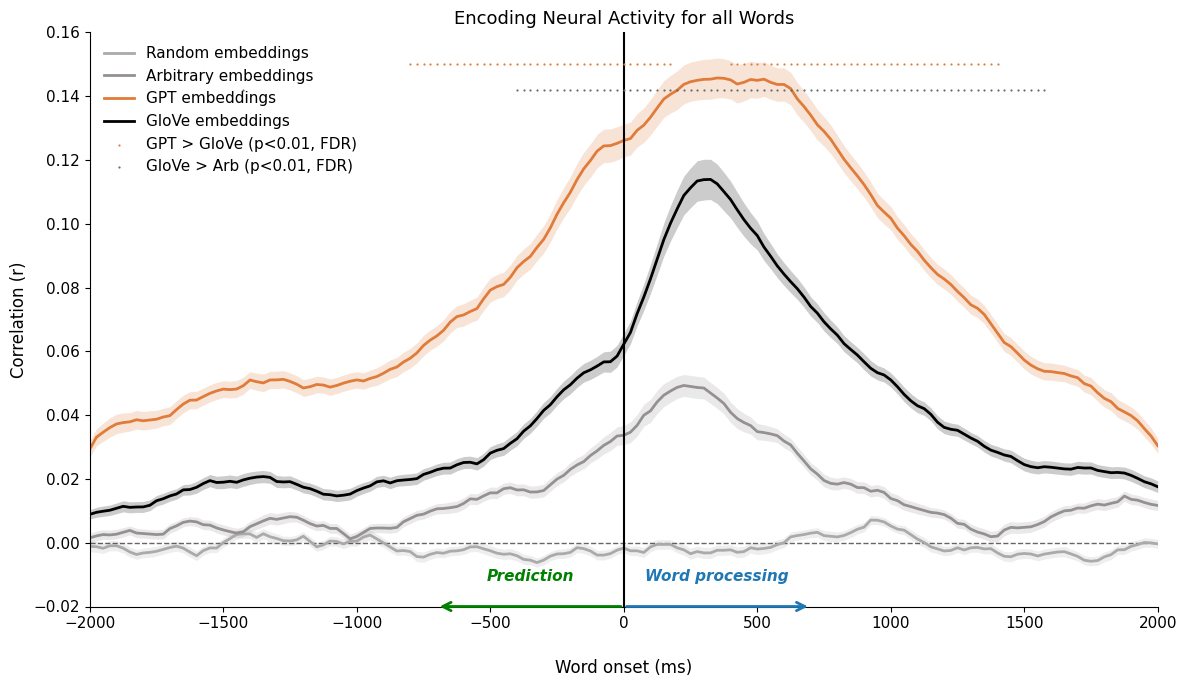

In [100]:
# ── Statistical testing: GPT > GloVe (sign-flip permutation + FDR) ──────────────
lags_ms     = np.linspace(-2000, 2000, 161)
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]

sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

r_glove_list, r_arb_list, r_rand_list, r_gpt_list = [], [], [], []

for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        continue
    sig_idx = sub_sig["elec_idx"].values
    try:
        g = np.load(f"corerlations_all{sid}.npy")[:, sig_idx, :].mean(axis=0)
        a = np.load(f"corrs_arb_{sid}.npy").mean(axis=0)
        r = np.load(f"corrs_rand_{sid}.npy").mean(axis=0)
        p = np.load(f"corrs_gpt_{sid}.npy").mean(axis=0)

        r_glove_list.append(g)
        r_arb_list.append(a)
        r_rand_list.append(r)
        r_gpt_list.append(p)
    except FileNotFoundError as e:
        print(f"sub-{sid}: missing file — {e}, skipping")

r_glove = np.concatenate(r_glove_list, axis=0)
r_arb   = np.concatenate(r_arb_list,   axis=0)
r_rand  = np.concatenate(r_rand_list,  axis=0)
r_gpt   = np.concatenate(r_gpt_list,   axis=0)
N_elec  = r_glove.shape[0]

print(f"Loaded {N_elec} significant electrodes across all subjects.")

# ── Statistical testing: GloVe > GPT (sign-flip permutation + FDR) ──────────────
# Mirrors exactly the GloVe-vs-Arbitrary test in the original plotting cell.

def permutation_test(r_a, r_b, N_PERMS=5000, seed=0, 
                     fdr_alpha=0.01, majority_thresh=0.50,
                     effect_quantile=0.50):   # ← new parameter
    diff        = r_a - r_b
    actual_mean = diff.mean(axis=0)
    pct_pos     = (diff > 0).mean(axis=0)

    rng            = np.random.default_rng(seed=seed)
    N_e            = diff.shape[0]
    signs_per_elec = rng.choice(np.array([-1, 1], dtype=np.float32),
                                size=(N_PERMS, N_e, 1))
    null_dist = (signs_per_elec * diff[np.newaxis, :, :]).mean(axis=1)

    p_vals = np.array(
        [(null_dist[:, t] >= actual_mean[t]).mean() for t in range(len(lags_ms))]
    )

    sig_fdr, _ = fdrcorrection(p_vals, alpha=fdr_alpha)

    # Effect size gate: only flag lags in the top (1 - effect_quantile) of the difference
    effect_threshold = np.quantile(actual_mean[actual_mean > 0], effect_quantile)
    large_effect     = actual_mean >= effect_threshold

    sig_final = sig_fdr & (pct_pos >= majority_thresh) & large_effect

    return sig_final, p_vals, pct_pos

# Run both comparisons

sig_gpt_vs_glove, _, _ = permutation_test(r_gpt, r_glove, seed=1)
sig_glove_vs_arb, _, _ = permutation_test(r_glove, r_arb,  seed=0)

# ── Plot ────────────────────────────────────────────────────────────────────────

def make_plot_all(sig_glove_vs_arb, sig_gpt_vs_glove):
    mean_glove = r_glove.mean(axis=0); se_glove = r_glove.std(axis=0) / np.sqrt(N_elec)
    mean_arb   = r_arb.mean(axis=0);   se_arb   = r_arb.std(axis=0)   / np.sqrt(N_elec)
    mean_rand  = r_rand.mean(axis=0);  se_rand  = r_rand.std(axis=0)  / np.sqrt(N_elec)
    mean_gpt   = r_gpt.mean(axis=0);   se_gpt   = r_gpt.std(axis=0)   / np.sqrt(N_elec)

    fig, ax = plt.subplots(figsize=(12, 7))

    curves = [
        ("#aaaaaa", mean_rand,  se_rand,  "Random"),
        ("#969191", mean_arb,   se_arb,   "Arbitrary"),
        ("#e07b39", mean_gpt,   se_gpt,   "GPT"),
        ("black",   mean_glove, se_glove, "GloVe"),
    ]

    for col, m, s, lab in curves:
        ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.2, linewidth=0)
        ax.plot(lags_ms, m, color=col, linewidth=2, label=f"{lab} embeddings")

    # Adjusted Y-axis limit to accommodate the GPT peak shown in your screenshot
    ax.set_ylim(-0.02, 0.16) 

    # Asterisk row 1: GPT > GloVe (Orange, placed high to clear the GPT curve)
    if sig_gpt_vs_glove.any():
        ax.scatter(lags_ms[sig_gpt_vs_glove],
                   np.full(sig_gpt_vs_glove.sum(), 0.150), # Higher placement
                   marker=".", s=10, color="#e07b39", linewidths=0, zorder=10,
                   label="GPT > GloVe (p<0.01, FDR)")

    # Asterisk row 2: GloVe > Arbitrary (Grey, placed just below GPT stars)
    if sig_glove_vs_arb.any():
        ax.scatter(lags_ms[sig_glove_vs_arb],
                   np.full(sig_glove_vs_arb.sum(), 0.142), 
                   marker=".", s=10, color="dimgrey", linewidths=0, zorder=10,
                   label="GloVe > Arb (p<0.01, FDR)")

    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6, zorder=1)
    ax.spines['bottom'].set_position(('data', -0.02))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Arrows and Labels
    ax.annotate('', xy=(-700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='green', lw=2, mutation_scale=15))
    ax.annotate('', xy=(700, -0.02), xytext=(0, -0.02),
                arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=2, mutation_scale=15))

    ax.text(-350, -0.012, "Prediction",     color="green",    style="italic",
            ha="center", fontweight='bold')
    ax.text( 350, -0.012, "Word processing", color="#1f77b4", style="italic",
            ha="center", fontweight='bold')

    ax.axvline(0, color="black", lw=1.5)
    ax.set_xlim(-2000, 2000)
    ax.set_xlabel("Word onset (ms)", fontsize=12, labelpad=20)
    ax.set_ylabel("Correlation (r)",     fontsize=12)
    ax.set_title("Encoding Neural Activity for all Words", fontsize=13)

    plt.legend(loc="upper left", frameon=False)
    plt.tight_layout()
    plt.savefig("novel_1.png", dpi=400, bbox_inches='tight')
    plt.savefig("novel_1.pdf", bbox_inches='tight')
    plt.show()

make_plot_all(sig_glove_vs_arb, sig_gpt_vs_glove)

In [16]:
df_glove.shape

(4867, 5)

In [17]:
df_glove.head(3)

,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."


In [18]:
df_gpt_final.shape

(4867, 12)

In [19]:
df_gpt_final.head(3)

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9688848, -2.7204232, -2.0838425, -4.468509...",act
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27876085, -0.85267466, -2.1737204, 0.67496...",one
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3147047, -3.9556947, 1.9342884, ...",monkey


In [20]:
df_glove

,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,in,4.951,5.011,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,the,5.051,5.111,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
...,...,...,...,...,...
5131,go,1798.546,1798.646,go,"[0.14828, 0.17761, 0.42346, -0.31489, 0.32273,..."
5132,to,1798.666,1798.746,to,"[0.68047, -0.039263, 0.30186, -0.17792, 0.4296..."
5133,court,1798.786,1799.006,court,"[-0.35445, -0.55181, -1.024, 0.59384, 0.57911,..."
5134,over,1799.046,1799.226,over,"[0.12972, 0.088073, 0.24375, 0.078102, -0.1278..."


In [22]:
df_gpt_final.head(14)

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9688848, -2.7204232, -2.0838425, -4.468509...",act
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27876085, -0.85267466, -2.1737204, 0.67496...",one
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3147047, -3.9556947, 1.9342884, ...",monkey
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,"[-6.756072, 2.8778949, 4.2936225, -1.2895249, ...",in
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,"[-6.889707, 5.5559106, -1.247399, 5.0973363, 6...",the
5,5,middle.,5.151,5.391,Ġmiddle,3504,0,0.172535,3504,5.194291,"[0.7765962, -3.6338117, -3.6629443, -1.9969082...",middle
6,6,So,6.592,6.732,ĠSo,1406,70,0.001563,198,5.696711,"[3.2514346, -0.7367451, 5.1918797, 0.19048457,...",so
8,8,some,6.892,7.052,Ġsome,617,12,0.012234,257,4.178666,"[-9.193684, 4.5103426, -0.36315665, 4.8068337,...",some
9,9,places,7.072,7.342,Ġplaces,4113,528,0.000243,286,7.322512,"[3.0235896, -5.0125976, 2.33146, 4.0893908, -2...",places
10,10,where,7.402,7.502,Ġwhere,810,0,0.310818,810,2.826031,"[-3.8203468, -1.8686708, 8.047854, -1.0304974,...",where


In [23]:
# Both dataframes have 4867 rows in the same order, so just assign directly
df_gpt_final['glove_embedding'] = df_glove['glove_embedding'].values

# Sanity check
print(f"Shape: {df_gpt_final.shape}")
print(f"NaN glove embeddings: {df_gpt_final['glove_embedding'].isna().sum()}")
print(df_gpt_final[['word', 'word_clean', 'gpt_embedding_50d', 'glove_embedding']].head(3))

Shape: (4867, 13)
NaN glove embeddings: 0
     word word_clean                                  gpt_embedding_50d  \
0     Act        act  [-1.9688848, -2.7204232, -2.0838425, -4.468509...   
1    one,        one  [-0.27876085, -0.85267466, -2.1737204, 0.67496...   
2  monkey     monkey  [-1.152554, 1.3147047, -3.9556947, 1.9342884, ...   

                                     glove_embedding  
0  [-0.60647, -0.65705, -1.1819, -0.61002, -0.197...  
1  [0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0...  
2  [0.28704, -0.60904, -0.74821, 0.17686, 0.92118...  


In [24]:
df_gpt_final.head(3)

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean,glove_embedding
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9688848, -2.7204232, -2.0838425, -4.468509...",act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27876085, -0.85267466, -2.1737204, 0.67496...",one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3147047, -3.9556947, 1.9342884, ...",monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."


## Creating different word category's dataset

In [25]:
# Now that there is the baseline comaparison and the embeddings for glove and gpt, we can now divide the words based on their categories
# =============================================================================
# CELL 1 — Load the external annotation files
# =============================================================================
# Using the spaCy analysis from the Nature dataset to catergorise the first two catergories: 
## Verbs vs nouns, functional vs non-functional words
# using Brysbaert concreteness ratings/ their dataset downloaded to categorise the third catergory: concrete vs abstract words


# --- Transcript with spaCy POS / stop-word tags (from the Nature dataset) ---
df_transcript = pd.read_csv(
    "stimuli/syntactic/transcript.tsv",   
    sep="\t"
)

# Keep one row per (word, start, end) triple.
# The transcript sometimes expands a single word into multiple tokens
# (e.g. "one," → "one" + ","); we take the first token's POS as the
# representative POS for the whole word.
df_transcript_dedup = (
    df_transcript
    .sort_values("word_idx")          # deterministic ordering
    .groupby(["word", "start", "end"], sort=False)
    .first()
    .reset_index()
)[["word", "start", "end", "pos", "stop"]]

print("Transcript (deduped) shape:", df_transcript_dedup.shape)
print(df_transcript_dedup.head(3))

# --- Brysbaert concreteness ratings ---
df_conc = pd.read_excel(
    "Concreteness_ratings_Brysbaert_et_al_BRM.xlsx"
)
# Rename for clarity; keep only the columns we need
df_conc = df_conc[["Word", "Conc.M"]].rename(
    columns={"Word": "word_clean", "Conc.M": "concreteness"}
)
df_conc["word_clean"] = df_conc["word_clean"].str.lower().str.strip()

print("\nConcreteness ratings shape:", df_conc.shape)
print(df_conc.head(3))

Transcript (deduped) shape: (5136, 5)
     word  start    end  pos   stop
0     Act  3.710  3.790  NNP  False
1    one,  3.990  4.190   CD   True
2  monkey  4.651  4.931   NN  False

Concreteness ratings shape: (39954, 2)
    word_clean  concreteness
0  roadsweeper          4.85
1  traindriver          4.54
2         tush          4.45


In [26]:
# =============================================================================
# CELL 2 — Merge POS / stop-word info into df_gpt_final
#           (df_glove uses the same word/start/end keys so the logic is identical)
# =============================================================================

# We merge on (word, start, end) — this uniquely identifies each word token
# in both df_gpt_final and the transcript
# that way we only have the glove words: 4867
## using df_gpt_final but could have also used glove, same result
df_merged = df_gpt_final.merge(
    df_transcript_dedup,
    on=["word", "start", "end"],
    how="left"
)

# Sanity check: how many rows got a POS tag?
matched = df_merged["pos"].notna().sum()
print(f"Words matched with POS annotation: {matched} / {len(df_merged)}")
print(df_merged[["word", "word_clean", "pos", "stop"]].head(5))


Words matched with POS annotation: 4867 / 4867
     word word_clean  pos   stop
0     Act        act  NNP  False
1    one,        one   CD   True
2  monkey     monkey   NN  False
3      in         in   IN   True
4     the        the   DT   True


In [27]:
# =============================================================================
# CELL 3 — Define POS-tag sets
# =============================================================================

# Penn Treebank tag sets used by spaCy

#in the POS column all words with these tags are considered verbs
VERB_TAGS  = {"VB", "VBD", "VBG", "VBN", "VBP", "VBZ"}   # all verb forms
#in the POS column all words with these tags are considered nouns
NOUN_TAGS  = {"NN", "NNS", "NNP", "NNPS"}                 # all noun forms

# Content words  = NOT stop words  (spaCy's stop column)/ FALSE
# Function words =     stop words /True

print("Verb tags :", VERB_TAGS)
print("Noun tags :", NOUN_TAGS)
print("\nSample stop=True  (function words):",
      df_merged[df_merged["stop"] == True]["word"].head(8).tolist())
print("Sample stop=False (content  words):",
      df_merged[df_merged["stop"] == False]["word"].head(8).tolist())

Verb tags : {'VB', 'VBZ', 'VBP', 'VBG', 'VBN', 'VBD'}
Noun tags : {'NNPS', 'NN', 'NNS', 'NNP'}

Sample stop=True  (function words): ['one,', 'in', 'the', 'So', 'some', 'where', 'almost', 'never']
Sample stop=False (content  words): ['Act', 'monkey', 'middle.', 'places', 'animals', 'places', 'designed', 'humans']


In [28]:
# =============================================================================
# CELL 4 — Create the five category dataframes
# =============================================================================

# ── 1. Verbs ──────────────────────────────────────────────────────────────────
df_verbs = (
    df_merged[df_merged["pos"].isin(VERB_TAGS)]
    .reset_index(drop=True)
)
print(f"Verbs      : {len(df_verbs):>5} rows")

# ── 2. Nouns ──────────────────────────────────────────────────────────────────
df_nouns = (
    df_merged[df_merged["pos"].isin(NOUN_TAGS)]
    .reset_index(drop=True)
)
print(f"Nouns      : {len(df_nouns):>5} rows")

# ── 3. Function words (stop words) ────────────────────────────────────────────
df_function = (
    df_merged[df_merged["stop"] == True]
    .reset_index(drop=True)
)
print(f"Function   : {len(df_function):>5} rows")

# ── 4. Content words (non-stop words) ─────────────────────────────────────────
df_content = (
    df_merged[df_merged["stop"] == False]
    .reset_index(drop=True)
)
print(f"Content    : {len(df_content):>5} rows")

Verbs      :   910 rows
Nouns      :  1165 rows
Function   :  2814 rows
Content    :  2053 rows


In [153]:
#All words were categorised as either function or content words
2814 + 2053

4867

In [154]:
#Some words were not verbs or nouns, they could be adjectives, adverbs, etc.
910 + 1165

2075

In [29]:
# Dataframe for abstract or concrete words (based on Brysbaert's concreteness ratings)
## decided to return the full set of words with a rating, so that different people can choose a cut-off; when a word is abtract versus not
# Match on word_clean (already lowercase, punctuation-stripped in df_gpt_final)
df_abstract_concrete = df_merged.merge(
    df_conc,
    on="word_clean",
    how="left"          # keep ALL words; NaN if not in Brysbaert's list
)
print(f"All words  : {len(df_abstract_concrete):>5} rows  "
      f"(concreteness rated: {df_abstract_concrete['concreteness'].notna().sum()})")

# Quick peek
print("\ndf_abstract_concrete sample:")
print(
    df_abstract_concrete[["word", "word_clean", "concreteness"]]
    .dropna(subset=["concreteness"])
    .head(5)
)

#based on this analysis you can see 4268 were kept from the origianl 4867 glove words

All words  :  4867 rows  (concreteness rated: 4268)

df_abstract_concrete sample:
     word word_clean  concreteness
0     Act        act          2.46
1    one,        one          3.97
2  monkey     monkey          4.90
3      in         in          3.00
4     the        the          1.43


In [30]:
df_abstract_concrete.shape

(4867, 16)

In [31]:
#Removing the NAN words/keeping only words that are in Brysbaert's concreteness ratings dataset
df_rated_only = df_abstract_concrete.dropna(subset=['concreteness'])

# Check the new size (smaller)
print(f"Rows remaining after removing NaNs: {len(df_rated_only)}")

# 1. Create the Abstract dataframe (Rating <= 2.5)
df_abstract = df_rated_only[df_rated_only['concreteness'] <= 2.5].copy()

# 2. Create the Concrete dataframe (Rating >= 4.0)
df_concrete = df_rated_only[df_rated_only['concreteness'] >= 4.0].copy()

# Print the results to check the sizes
print(f"Abstract words (<= 2.5): {len(df_abstract)}")
print(f"Concrete words (>= 4.0): {len(df_concrete)}")

Rows remaining after removing NaNs: 4268
Abstract words (<= 2.5): 2447
Concrete words (>= 4.0): 453


In [32]:
#As you can see there is a data imbalance
#to fix this issue: Only perform this analysis on Lexical (Content) words
#To make it fair this must be for both:

# 1. Filter df_concrete to keep ONLY lexical words (stop == False)
df_concrete_lexical = df_concrete[df_concrete['stop'] == False].copy()

# 2. Do the same for df_abstract so your comparison is consistent
df_abstract_lexical = df_abstract[df_abstract['stop'] == False].copy()

# Print the new counts
print(f"Lexical Abstract words: {len(df_abstract_lexical)}")
print(f"Lexical Concrete words: {len(df_concrete_lexical)}")


Lexical Abstract words: 479
Lexical Concrete words: 369


## Running Encoding 


In [135]:
df_verbs.shape

(910, 15)

In [136]:
df_nouns.shape

(1165, 15)

In [137]:
df_function.shape

(2814, 15)

In [138]:
df_content.shape

(2053, 15)

In [33]:
#Now that we have the categories, we can get the embeddings for each category and run the encoding model for each category separately
#For now I will calculate correltions separately for glove vs gpt
import ast

####### GPT EMBEDDINGS ####
def parse_embedding(emb):
    """Parse embedding whether stored as a list or as a string repr of a list."""
    if isinstance(emb, list):
        return np.array(emb, dtype=float)
    if isinstance(emb, str):
        return np.array(ast.literal_eval(emb), dtype=float)
    return np.array(emb, dtype=float)

# Stack embeddings into 2-D arrays  (n_words × embedding_dim)
gpt_emb_verbs    = np.vstack(df_verbs["gpt_embedding_50d"].apply(parse_embedding))
gpt_emb_nouns    = np.vstack(df_nouns["gpt_embedding_50d"].apply(parse_embedding))
gpt_emb_function = np.vstack(df_function["gpt_embedding_50d"].apply(parse_embedding))
gpt_emb_content  = np.vstack(df_content["gpt_embedding_50d"].apply(parse_embedding))
gpt_emb_abstract   = np.vstack(df_abstract_lexical["gpt_embedding_50d"].apply(parse_embedding))
gpt_emb_concre     = np.vstack(df_concrete_lexical["gpt_embedding_50d"].apply(parse_embedding))

print("GPT embedding shapes:")
print(f"  Verbs    : {gpt_emb_verbs.shape}")
print(f"  Nouns    : {gpt_emb_nouns.shape}")
print(f"  Function : {gpt_emb_function.shape}")
print(f"  Content  : {gpt_emb_content.shape}")
print(f"  Abstract      : {gpt_emb_abstract.shape}")
print(f"  Concrete      : {gpt_emb_concre.shape}")

GPT embedding shapes:
  Verbs    : (910, 50)
  Nouns    : (1165, 50)
  Function : (2814, 50)
  Content  : (2053, 50)
  Abstract      : (479, 50)
  Concrete      : (369, 50)


In [36]:
# Repeat the same for GloVe embeddings
glove_emb_verbs    = np.vstack(df_verbs["glove_embedding"].apply(parse_embedding))
glove_emb_nouns    = np.vstack(df_nouns["glove_embedding"].apply(parse_embedding))
glove_emb_function = np.vstack(df_function["glove_embedding"].apply(parse_embedding))
glove_emb_content  = np.vstack(df_content["glove_embedding"].apply(parse_embedding))
glove_emb_abstract = np.vstack(df_abstract_lexical["glove_embedding"].apply(parse_embedding))
glove_emb_concrete = np.vstack(df_concrete_lexical["glove_embedding"].apply(parse_embedding))

print("GloVe embedding shapes:")
print(f"  Verbs        : {glove_emb_verbs.shape}")
print(f"  Nouns        : {glove_emb_nouns.shape}")
print(f"  Function     : {glove_emb_function.shape}")
print(f"  Content      : {glove_emb_content.shape}")
print(f"  Abstract (L) : {glove_emb_abstract.shape}")
print(f"  Concrete (L) : {glove_emb_concrete.shape}")

GloVe embedding shapes:
  Verbs        : (910, 50)
  Nouns        : (1165, 50)
  Function     : (2814, 50)
  Content      : (2053, 50)
  Abstract (L) : (479, 50)
  Concrete (L) : (369, 50)


In [38]:
# creating a new folder for our correlations
os.makedirs("new_hypothesis_correlations", exist_ok=True)
print("Output folder ready: new_hypothesis_correlations/")

# Naming convention:
#   new_hypothesis_correlations/corrs_{embedding}_{category}_{sid}.npy
#   e.g. corrs_gpt_verbs_02.npy, corrs_glove_abstract_05.npy

Output folder ready: new_hypothesis_correlations/


In [ ]:
# Identical pipeline to existing code, but parameterised:
#   df_cat    → the category-specific dataframe (to get word onset times)
#   X_cat     → the pre-stacked embedding matrix for that category (n_words × dim)
#   label     → string used in the save filename, e.g. "gpt_verbs"

def run_category_encoding(df_cat, X_cat, label, sid,
                          sig_indices, bids_root,
                          save_dir="new_hypothesis_correlations"):

    # ── Load raw, pick left-hemisphere significant electrodes ─────────────────
    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    ch2loc      = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm   = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask     = coords_mm[:, 0] < 0
    lh_ch_names = [ch for ch, keep in zip(raw.ch_names, lh_mask) if keep]
    raw         = raw.copy().pick(lh_ch_names)

    sig_ch_names = [raw.ch_names[i] for i in sig_indices]
    raw          = raw.copy().pick(sig_ch_names)

    # ── Build epochs using THIS category's word onset times ───────────────────
    sfreq  = raw.info['sfreq']
    events = np.zeros((len(df_cat), 3), dtype=int)
    events[:, 0] = (df_cat['start'].values * sfreq).astype(int)

    epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                        baseline=None, proj=False, event_id=None,
                        preload=True, event_repeated="merge")

    # ── Window averaging → (n_words_kept, n_sig_elec, 161) ───────────────────
    times       = epochs.times
    lag_centers = np.arange(-2.0, 2.0 + 0.025 / 2, 0.025)
    WIN_HALF    = 0.100
    lag_masks   = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                   for τ in lag_centers]

    epochs_data             = epochs.get_data(copy=True)
    n_words_kept, n_sig_elec, _ = epochs_data.shape
    epochs_shape            = (n_sig_elec, 161)

    epochs_windowed = np.stack(
        [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
    ).astype(np.float32)

    Y = epochs_windowed.reshape(n_words_kept, n_sig_elec * 161)
    if "torch" in get_backend().__name__:
        Y = Y.astype(np.float32)

    # ── Align embeddings to the epochs that were actually kept ────────────────
    X_sel = X_cat[epochs.selection].astype("float32")

    # ── Train encoding model ──────────────────────────────────────────────────
    corrs = train_encoding(X_sel, Y, epochs_shape)   # uses your existing function

    # ── Save ──────────────────────────────────────────────────────────────────
    fname = os.path.join(save_dir, f"corrs_{label}_{sid}.npy")
    np.save(fname, corrs)
    print(f"    Saved {fname}  shape: {corrs.shape}")

    return corrs

In [ ]:
#Re-writing the above code just in case the previous analysis was not re-runed (e.g. this cell was created on another day, to not have to re-run the previous correlations, run this cell)
lags_ms     = np.linspace(-2000, 2000, 161)
alphas      = np.logspace(1, 10, 10)
inner_cv    = KFold(n_splits=5, shuffle=False)
model       = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)

def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)



In [43]:
# ── Run encoding for every category × embedding × subject ─────────────
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]

sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

# Map: label → (dataframe, embedding_matrix)
# Each entry is  (df_category, X_matrix)
categories = {
    # GPT embeddings
    "gpt_verbs"    : (df_verbs,           gpt_emb_verbs),
    "gpt_nouns"    : (df_nouns,           gpt_emb_nouns),
    "gpt_function" : (df_function,        gpt_emb_function),
    "gpt_content"  : (df_content,         gpt_emb_content),
    "gpt_abstract" : (df_abstract_lexical, gpt_emb_abstract),
    "gpt_concrete" : (df_concrete_lexical, gpt_emb_concre),
    # GloVe embeddings
    "glove_verbs"    : (df_verbs,           glove_emb_verbs),
    "glove_nouns"    : (df_nouns,           glove_emb_nouns),
    "glove_function" : (df_function,        glove_emb_function),
    "glove_content"  : (df_content,         glove_emb_content),
    "glove_abstract" : (df_abstract_lexical, glove_emb_abstract),
    "glove_concrete" : (df_concrete_lexical, glove_emb_concrete),
}

# Store all results: results[label] = list of per-subject correlation arrays
results = {label: [] for label in categories}

for sid in subject_ids:
    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values
    print(f"\n── sub-{sid}: {len(sig_indices)} significant electrodes ──")

    for label, (df_cat, X_cat) in categories.items():
        print(f"  Running {label}  ({len(df_cat)} words, emb dim {X_cat.shape[1]})")
        corrs = run_category_encoding(
            df_cat, X_cat, label, sid,
            sig_indices=sig_indices,
            bids_root=bids_root
        )
        results[label].append(corrs)

print("\n✓ All encodings complete.")

sub-02: no significant electrodes, skipping

── sub-03: 41 significant electrodes ──
  Running gpt_verbs  (910 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_verbs_03.npy  shape: (10, 41, 161)
  Running gpt_nouns  (1165 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_nouns_03.npy  shape: (10, 41, 161)
  Running gpt_function  (2814 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_function_03.npy  shape: (10, 41, 161)
  Running gpt_content  (2053 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_content_03.npy  shape: (10, 41, 161)
  Running gpt_abstract  (479 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_abstract_03.npy  shape: (10, 41, 161)
  Running gpt_concrete  (369 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_gpt_concrete_03.npy  shape: (10, 41, 161)
  Running glove_verbs  (910 words, emb dim 50)
    Saved new_hypothesis_correlations/corrs_glove_verbs_03.npy  shape: (10,

In [44]:
# ──  Aggregate correlations across subjects ────────────────────────────
# For each label: concatenate across subjects (along electrode axis), average folds

def aggregate(label):
    """Load from disk (or use in-memory results) and return (n_elec, 161) mean."""
    arrays = []
    for sid in subject_ids:
        fpath = f"new_hypothesis_correlations/corrs_{label}_{sid}.npy"
        if os.path.exists(fpath):
            arr = np.load(fpath)          # (n_folds, n_sig_elec, 161)
            arrays.append(arr.mean(axis=0))   # → (n_sig_elec, 161)
    return np.concatenate(arrays, axis=0)     # → (total_elec, 161)

r = {label: aggregate(label) for label in categories}
N = {label: r[label].shape[0] for label in categories}
print({k: v.shape for k, v in r.items()})

{'gpt_verbs': (174, 161), 'gpt_nouns': (174, 161), 'gpt_function': (174, 161), 'gpt_content': (174, 161), 'gpt_abstract': (174, 161), 'gpt_concrete': (174, 161), 'glove_verbs': (174, 161), 'glove_nouns': (174, 161), 'glove_function': (174, 161), 'glove_content': (174, 161), 'glove_abstract': (174, 161), 'glove_concrete': (174, 161)}



=== Verbs vs Nouns ===
  [GLOVE] verbs > nouns:
    p_vals min=0.0000  sig_fdr=9  pct_pos gate=29  final=9
  [GLOVE] nouns > verbs:
    p_vals min=0.0000  sig_fdr=113  pct_pos gate=134  final=113
  [GPT] verbs > nouns:
    p_vals min=0.0002  sig_fdr=3  pct_pos gate=24  final=3
  [GPT] nouns > verbs:
    p_vals min=0.0000  sig_fdr=110  pct_pos gate=138  final=110


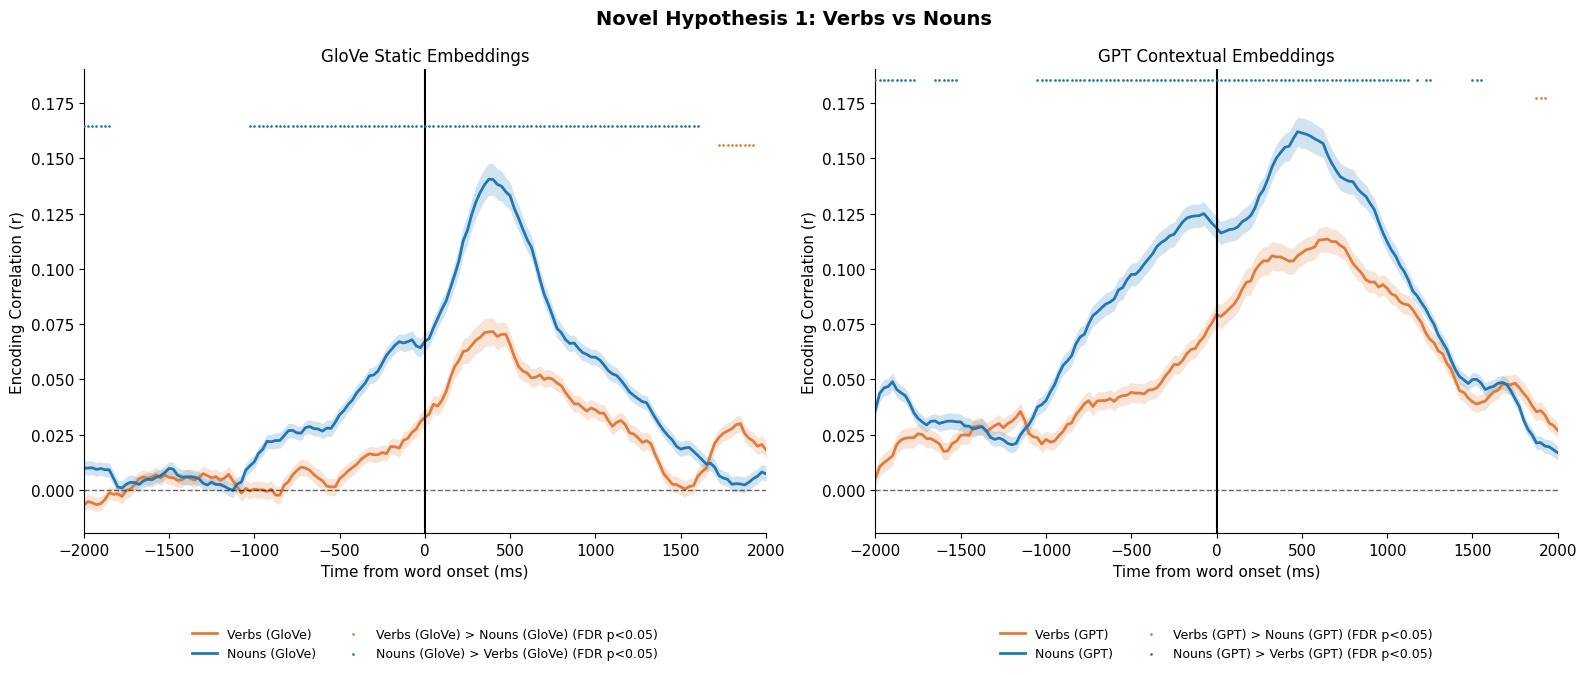


=== Function vs Content ===
  [GLOVE] function > content:
    p_vals min=0.0000  sig_fdr=15  pct_pos gate=50  final=15
  [GLOVE] content > function:
    p_vals min=0.0000  sig_fdr=82  pct_pos gate=114  final=82
  [GPT] function > content:
    p_vals min=0.0000  sig_fdr=23  pct_pos gate=37  final=23
  [GPT] content > function:
    p_vals min=0.0000  sig_fdr=107  pct_pos gate=125  final=107


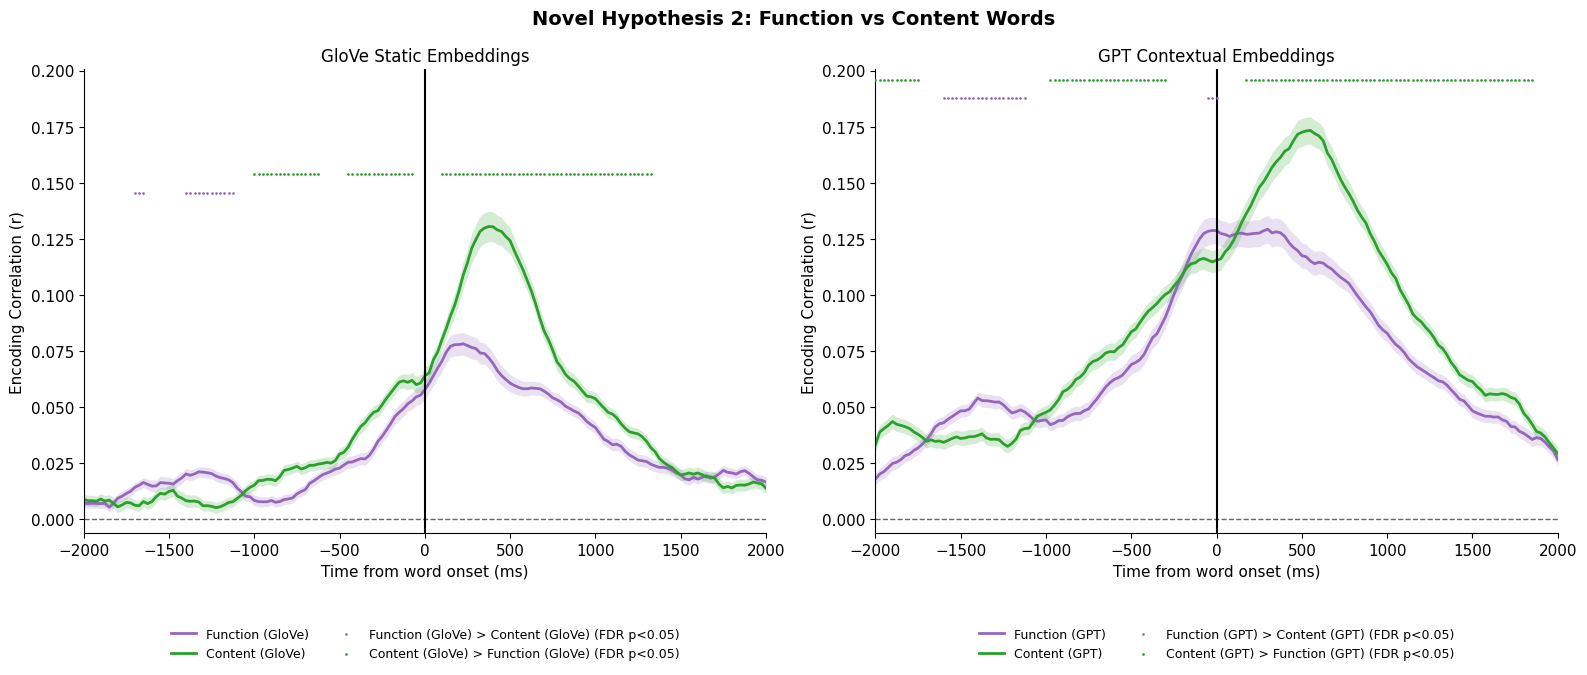


=== Abstract vs Concrete ===
  [GLOVE] abstract > concrete:
    p_vals min=0.0014  sig_fdr=0  pct_pos gate=83  final=0
  [GLOVE] concrete > abstract:
    p_vals min=0.0000  sig_fdr=21  pct_pos gate=84  final=21
  [GPT] abstract > concrete:
    p_vals min=0.0000  sig_fdr=18  pct_pos gate=50  final=18
  [GPT] concrete > abstract:
    p_vals min=0.0000  sig_fdr=80  pct_pos gate=115  final=80


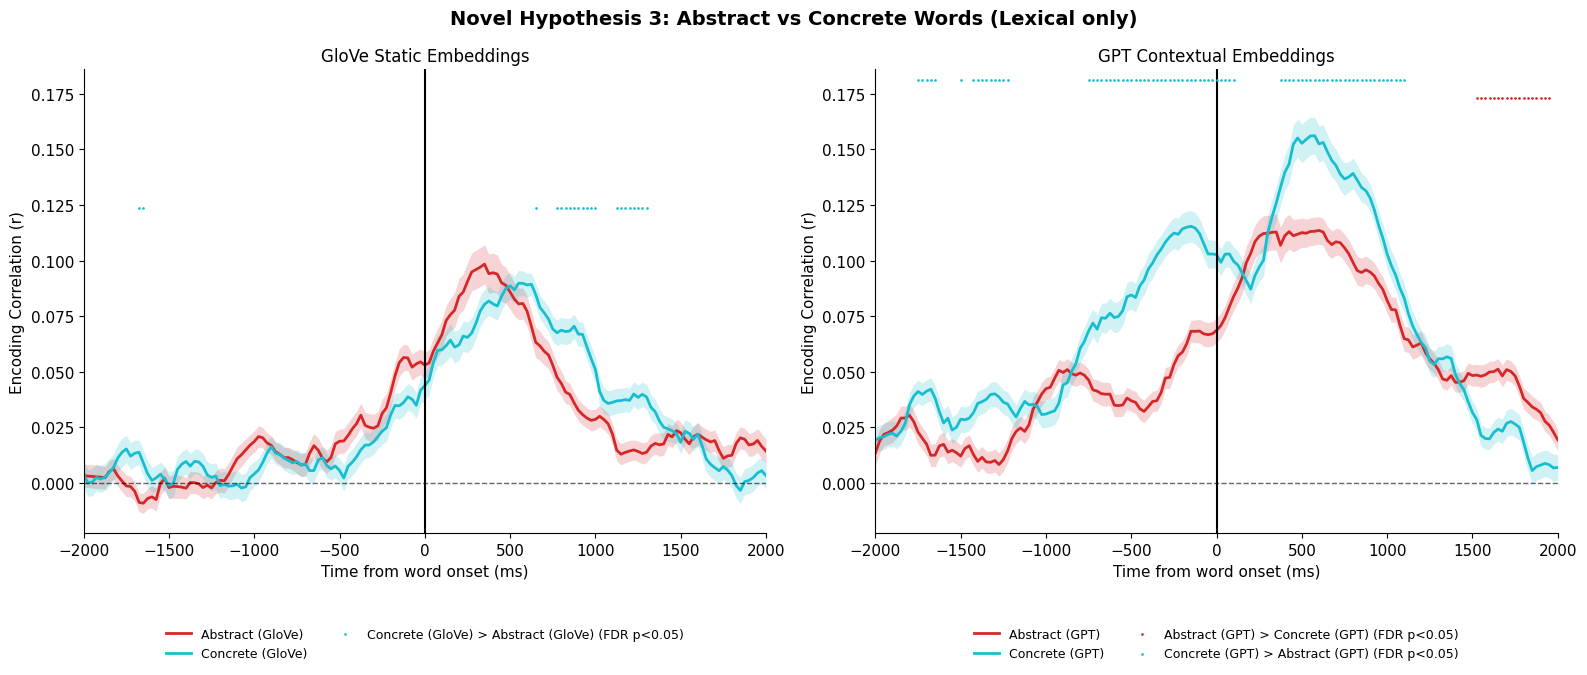


All figures saved.


In [ ]:
############# PLOTTING

lags_ms = np.linspace(-2000, 2000, 161)

COLOURS = {
    "verbs"    : "#e07b39",
    "nouns"    : "#1f77b4",
    "function" : "#9467bd",
    "content"  : "#2ca02c",
    "abstract" : "#d62728",
    "concrete" : "#17becf",
}

def permutation_test_pair(r_a, r_b, N_PERMS=5000, seed=0,
                          fdr_alpha=0.05, majority_thresh=0.50):
    """
    majority_thresh=0.50 means just over half of electrodes must agree.
    This matches what the paper uses and avoids over-filtering moderate effects.
    """
    n    = min(r_a.shape[0], r_b.shape[0])
    r_a  = r_a[:n]
    r_b  = r_b[:n]
    diff = r_a - r_b

    actual_mean = diff.mean(axis=0)
    pct_pos     = (diff > 0).mean(axis=0)

    rng   = np.random.default_rng(seed=seed)
    signs = rng.choice(np.array([-1, 1], dtype=np.float32),
                       size=(N_PERMS, n, 1))
    null  = (signs * diff[np.newaxis]).mean(axis=1)

    p_vals     = np.array([(null[:, t] >= actual_mean[t]).mean()
                            for t in range(len(lags_ms))])
    sig_fdr, _ = fdrcorrection(p_vals, alpha=fdr_alpha)
    sig_final  = sig_fdr & (pct_pos >= majority_thresh)

    print(f"    p_vals min={p_vals.min():.4f}  "
          f"sig_fdr={sig_fdr.sum()}  "
          f"pct_pos gate={( pct_pos >= majority_thresh).sum()}  "
          f"final={sig_final.sum()}")
    return sig_final


def compute_shared_ylims(cat_a, cat_b, padding_top=0.12, padding_bot=0.05):
    all_means, all_ses = [], []
    for emb in ["glove", "gpt"]:
        for cat in [cat_a, cat_b]:
            key = f"{emb}_{cat}"
            m   = r[key].mean(axis=0)
            s   = r[key].std(axis=0) / np.sqrt(N[key])
            all_means.append(m)
            all_ses.append(s)
    global_max = max((m + s).max() for m, s in zip(all_means, all_ses))
    global_min = min((m - s).min() for m, s in zip(all_means, all_ses))
    y_range    = global_max - global_min
    return global_min - padding_bot * y_range, global_max + padding_top * y_range


def plot_category_pair(ax, emb_type, cat_a, cat_b,
                       label_a, label_b, title,
                       y_min, y_max):

    key_a = f"{emb_type}_{cat_a}"
    key_b = f"{emb_type}_{cat_b}"

    ra, rb = r[key_a], r[key_b]
    na, nb = N[key_a], N[key_b]
    col_a  = COLOURS[cat_a]
    col_b  = COLOURS[cat_b]

    mean_a = ra.mean(axis=0);  se_a = ra.std(axis=0) / np.sqrt(na)
    mean_b = rb.mean(axis=0);  se_b = rb.std(axis=0) / np.sqrt(nb)

    # ── Plot curves ───────────────────────────────────────────────────────────
    for col, m, s, lab in [(col_a, mean_a, se_a, label_a),
                            (col_b, mean_b, se_b, label_b)]:
        ax.fill_between(lags_ms, m - s, m + s,
                        color=col, alpha=0.2, linewidth=0)
        ax.plot(lags_ms, m, color=col, linewidth=2, label=lab)

    # ── Significance tests ────────────────────────────────────────────────────
    print(f"  [{emb_type.upper()}] {cat_a} > {cat_b}:")
    sig_ab = permutation_test_pair(ra, rb, seed=42)
    print(f"  [{emb_type.upper()}] {cat_b} > {cat_a}:")
    sig_ba = permutation_test_pair(rb, ra, seed=43)

    # Dot markers exactly like your baseline figure —
    # two rows just above the curves, below the top of the axis
    curve_top = max((mean_a + se_a).max(), (mean_b + se_b).max())
    y_range   = y_max - y_min
    row_a     = curve_top + 0.04 * y_range   # cat_a > cat_b  (lower row)
    row_b     = curve_top + 0.08 * y_range   # cat_b > cat_a  (upper row)

    if sig_ab.any():
        ax.scatter(lags_ms[sig_ab],
                   np.full(sig_ab.sum(), row_a),
                   marker=".", s=15, color=col_a,
                   linewidths=0, zorder=10,
                   label=f"{label_a} > {label_b} (FDR p<0.05)")
    if sig_ba.any():
        ax.scatter(lags_ms[sig_ba],
                   np.full(sig_ba.sum(), row_b),
                   marker=".", s=15, color=col_b,
                   linewidths=0, zorder=10,
                   label=f"{label_b} > {label_a} (FDR p<0.05)")

    # ── Aesthetics ────────────────────────────────────────────────────────────
    ax.set_ylim(y_min, y_max)
    ax.axhline(0, color="black", lw=1.0, ls="--", alpha=0.6)
    ax.axvline(0, color="black", lw=1.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(-2000, 2000)
    ax.set_xlabel("Time from word onset (ms)", fontsize=11)
    ax.set_ylabel("Encoding Correlation (r)",  fontsize=11)
    ax.set_title(title, fontsize=12)

    # Legend BELOW the plot — never overlaps curves or sig markers
    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, -0.18),   # centred, below x-axis
              frameon=False,
              fontsize=9,
              ncol=2)                         # two columns to keep it compact


# =============================================================================
# Figure 1: Verbs vs Nouns
# =============================================================================
print("\n=== Verbs vs Nouns ===")
y_min, y_max = compute_shared_ylims("verbs", "nouns")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))   # extra height for legend
fig.suptitle("Novel Hypothesis 1: Verbs vs Nouns",
             fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "verbs", "nouns",
                   "Verbs (GloVe)", "Nouns (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "verbs", "nouns",
                   "Verbs (GPT)",   "Nouns (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_verbs_vs_nouns.png",
            dpi=150, bbox_inches="tight")
plt.show()

# =============================================================================
# Figure 2: Function vs Content
# =============================================================================
print("\n=== Function vs Content ===")
y_min, y_max = compute_shared_ylims("function", "content")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Novel Hypothesis 2: Function vs Content Words",
             fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "function", "content",
                   "Function (GloVe)", "Content (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "function", "content",
                   "Function (GPT)",   "Content (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_function_vs_content.png",
            dpi=150, bbox_inches="tight")
plt.show()

# =============================================================================
# Figure 3: Abstract vs Concrete
# =============================================================================
print("\n=== Abstract vs Concrete ===")
y_min, y_max = compute_shared_ylims("abstract", "concrete")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Novel Hypothesis 3: Abstract vs Concrete Words (Lexical only)",
             fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "abstract", "concrete",
                   "Abstract (GloVe)", "Concrete (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "abstract", "concrete",
                   "Abstract (GPT)",   "Concrete (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_abstract_vs_concrete.png",
            dpi=150, bbox_inches="tight")
plt.show()

print("\nAll figures saved.")


=== Verbs vs Nouns ===
  [GLOVE] verbs > nouns:
    p_vals min=0.0000  sig_fdr=9  pct_pos gate=29  final=9
  [GLOVE] nouns > verbs:
    p_vals min=0.0000  sig_fdr=113  pct_pos gate=134  final=113
  [GPT] verbs > nouns:
    p_vals min=0.0002  sig_fdr=3  pct_pos gate=24  final=3
  [GPT] nouns > verbs:
    p_vals min=0.0000  sig_fdr=110  pct_pos gate=138  final=110


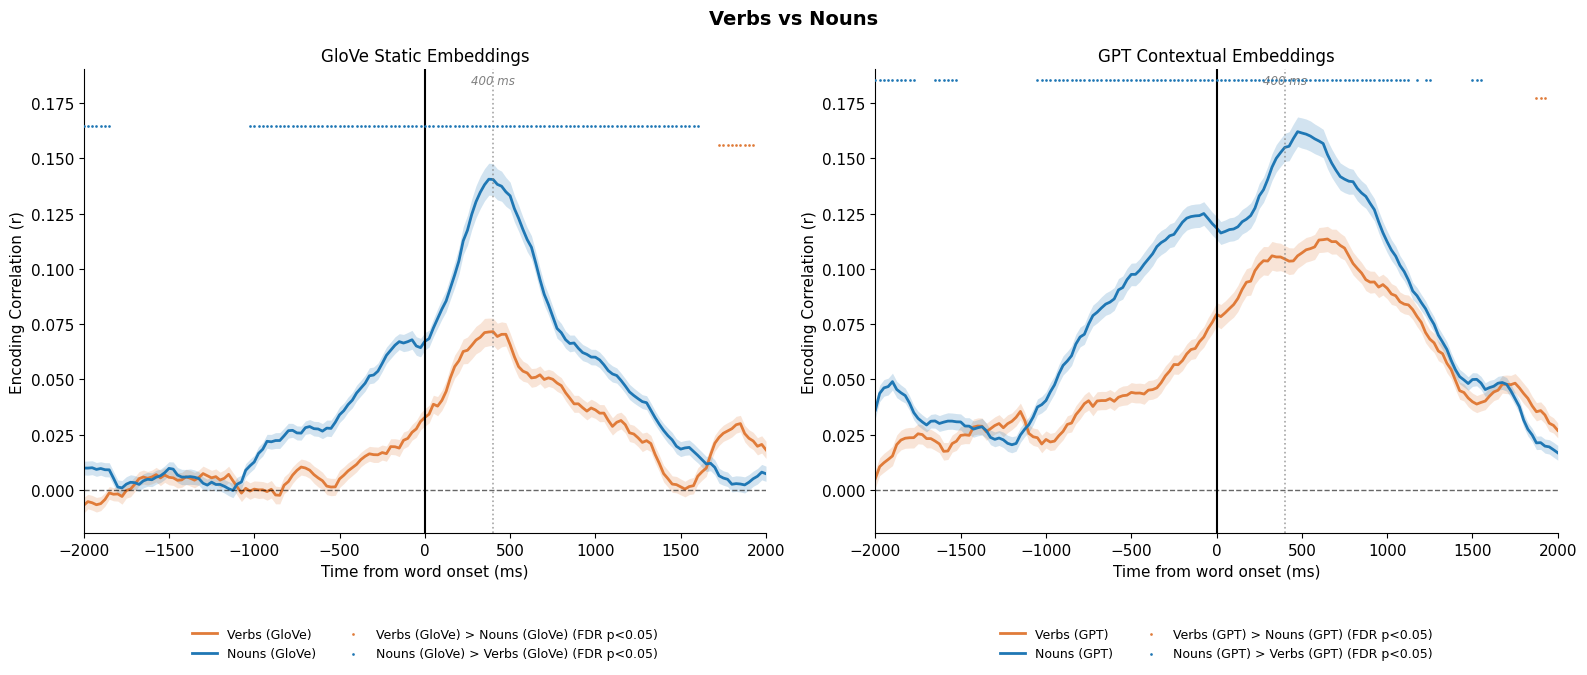


=== Function vs Content ===
  [GLOVE] function > content:
    p_vals min=0.0000  sig_fdr=15  pct_pos gate=50  final=15
  [GLOVE] content > function:
    p_vals min=0.0000  sig_fdr=82  pct_pos gate=114  final=82
  [GPT] function > content:
    p_vals min=0.0000  sig_fdr=23  pct_pos gate=37  final=23
  [GPT] content > function:
    p_vals min=0.0000  sig_fdr=107  pct_pos gate=125  final=107


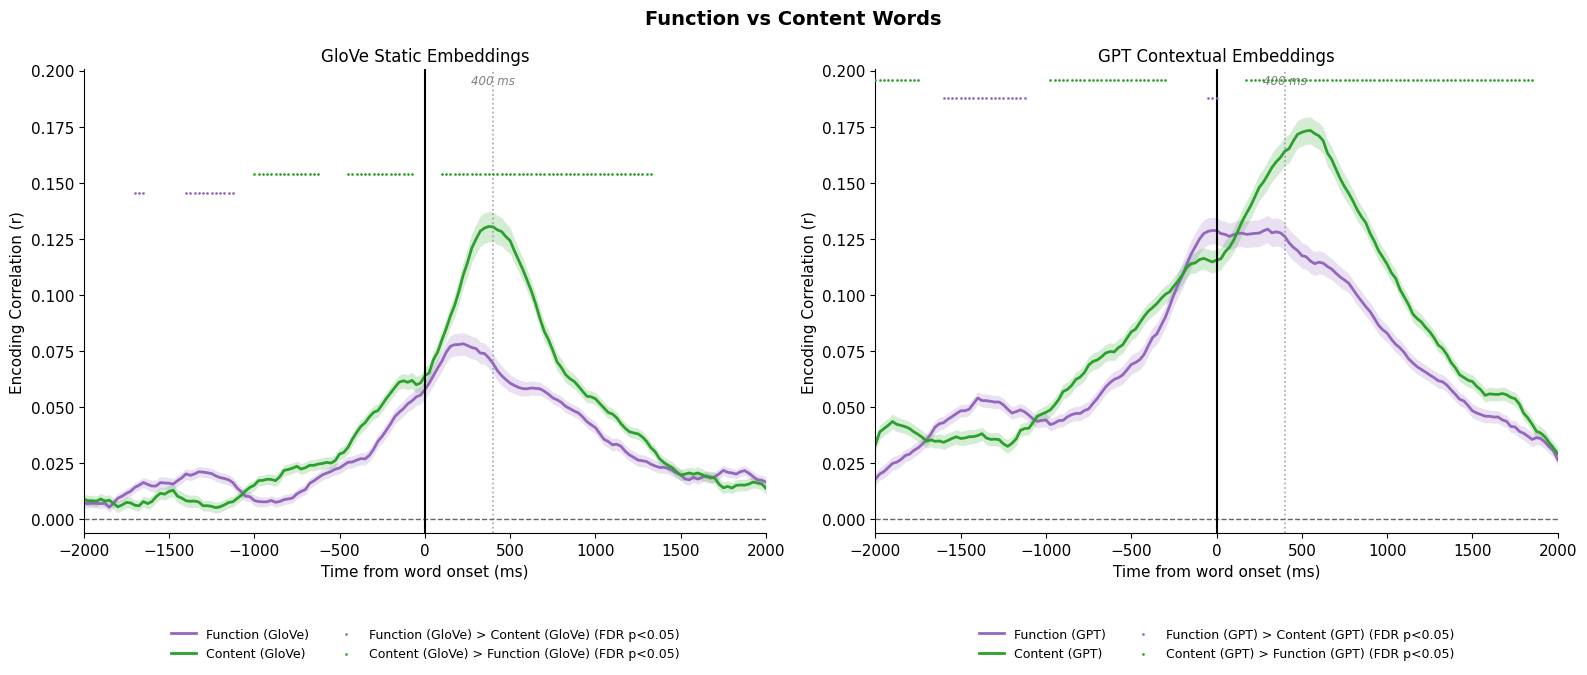


=== Abstract vs Concrete ===
  [GLOVE] abstract > concrete:
    p_vals min=0.0014  sig_fdr=0  pct_pos gate=83  final=0
  [GLOVE] concrete > abstract:
    p_vals min=0.0000  sig_fdr=21  pct_pos gate=84  final=21
  [GPT] abstract > concrete:
    p_vals min=0.0000  sig_fdr=18  pct_pos gate=50  final=18
  [GPT] concrete > abstract:
    p_vals min=0.0000  sig_fdr=80  pct_pos gate=115  final=80


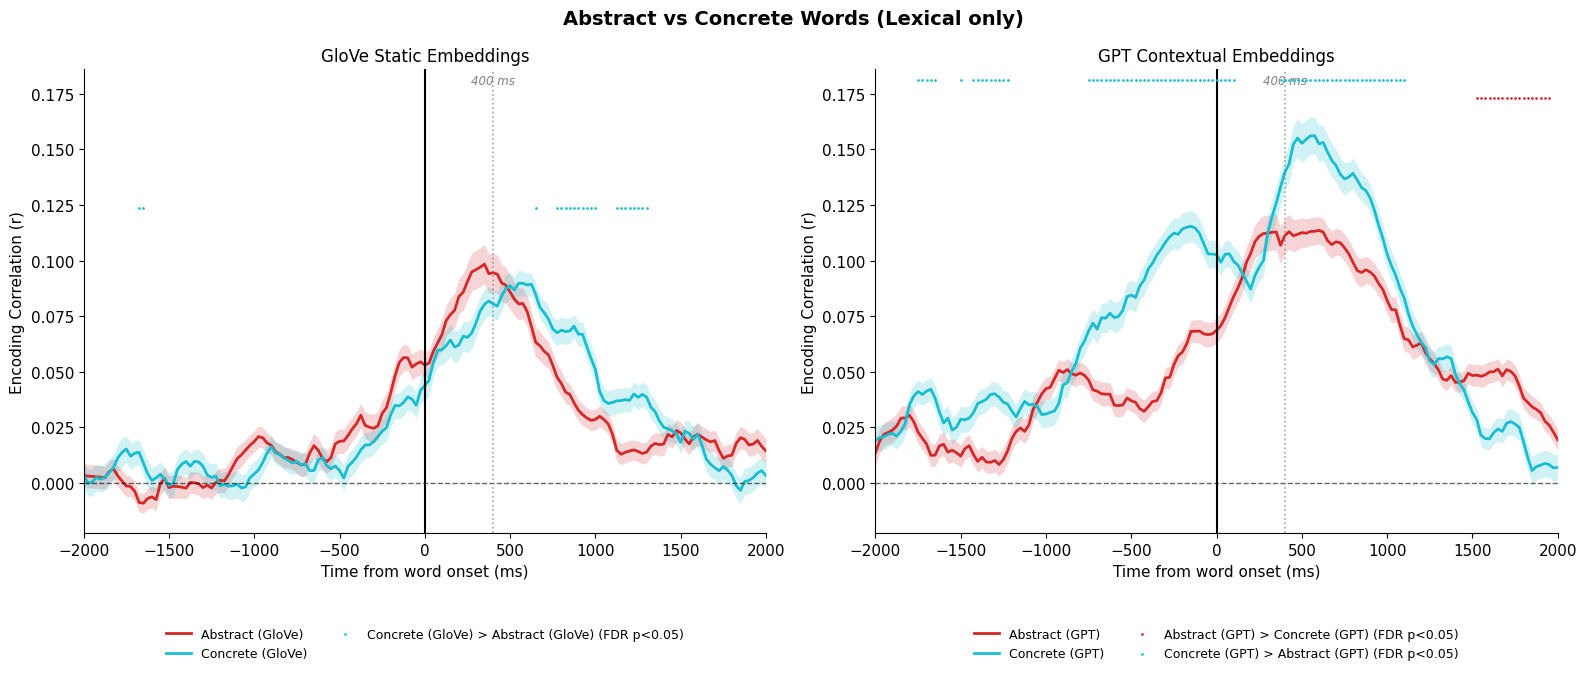


All figures saved.


In [105]:
# Rename your results dictionary from r → results_dict
# and N → n_elec_dict
# Do this once, then update the plotting code to match

# When you built the results, you had something like:
# r = {label: aggregate(label) for label in categories}
# N = {label: r[label].shape[0] for label in categories}
# Change those to:
results_dict = {label: aggregate(label) for label in CATEGORIES}
n_elec_dict  = {label: results_dict[label].shape[0] for label in CATEGORIES}

def compute_shared_ylims(cat_a, cat_b, padding_top=0.12, padding_bot=0.05):
    all_means, all_ses = [], []
    for emb in ["glove", "gpt"]:
        for cat in [cat_a, cat_b]:
            key = f"{emb}_{cat}"
            m   = results_dict[key].mean(axis=0)
            s   = results_dict[key].std(axis=0) / np.sqrt(n_elec_dict[key])
            all_means.append(m)
            all_ses.append(s)
    global_max = max((m + s).max() for m, s in zip(all_means, all_ses))
    global_min = min((m - s).min() for m, s in zip(all_means, all_ses))
    y_range    = global_max - global_min
    return global_min - padding_bot * y_range, global_max + padding_top * y_range


def plot_category_pair(ax, emb_type, cat_a, cat_b,
                       label_a, label_b, title,
                       y_min, y_max):

    key_a = f"{emb_type}_{cat_a}"
    key_b = f"{emb_type}_{cat_b}"

    ra = results_dict[key_a]
    rb = results_dict[key_b]
    na = n_elec_dict[key_a]
    nb = n_elec_dict[key_b]
    col_a  = COLOURS[cat_a]
    col_b  = COLOURS[cat_b]

    mean_a = ra.mean(axis=0);  se_a = ra.std(axis=0) / np.sqrt(na)
    mean_b = rb.mean(axis=0);  se_b = rb.std(axis=0) / np.sqrt(nb)

    for col, m, s, lab in [(col_a, mean_a, se_a, label_a),
                            (col_b, mean_b, se_b, label_b)]:
        ax.fill_between(lags_ms, m - s, m + s,
                        color=col, alpha=0.2, linewidth=0)
        ax.plot(lags_ms, m, color=col, linewidth=2, label=lab)

    print(f"  [{emb_type.upper()}] {cat_a} > {cat_b}:")
    sig_ab = permutation_test_pair(ra, rb, seed=42)
    print(f"  [{emb_type.upper()}] {cat_b} > {cat_a}:")
    sig_ba = permutation_test_pair(rb, ra, seed=43)

    curve_top = max((mean_a + se_a).max(), (mean_b + se_b).max())
    y_range   = y_max - y_min
    row_a     = curve_top + 0.04 * y_range
    row_b     = curve_top + 0.08 * y_range

    if sig_ab.any():
        ax.scatter(lags_ms[sig_ab],
                   np.full(sig_ab.sum(), row_a),
                   marker=".", s=15, color=col_a,
                   linewidths=0, zorder=10,
                   label=f"{label_a} > {label_b} (FDR p<0.05)")
    if sig_ba.any():
        ax.scatter(lags_ms[sig_ba],
                   np.full(sig_ba.sum(), row_b),
                   marker=".", s=15, color=col_b,
                   linewidths=0, zorder=10,
                   label=f"{label_b} > {label_a} (FDR p<0.05)")

    ax.axhline(0,   color="black", lw=1.0, ls="--", alpha=0.6)
    ax.axvline(0,   color="black", lw=1.5)
    ax.axvline(400, color="grey",  lw=1.2, ls=":",  alpha=0.7)
    ax.text(400, y_max - 0.01 * y_range, "400 ms",
            ha="center", va="top", fontsize=8.5,
            color="grey", style="italic")

    ax.set_ylim(y_min, y_max)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xlim(-2000, 2000)
    ax.set_xlabel("Time from word onset (ms)", fontsize=11)
    ax.set_ylabel("Encoding Correlation (r)",  fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, -0.18),
              frameon=False, fontsize=9, ncol=2)


# =============================================================================
# Figure 1: Verbs vs Nouns
# =============================================================================
print("\n=== Verbs vs Nouns ===")
y_min, y_max = compute_shared_ylims("verbs", "nouns")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Verbs vs Nouns", fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "verbs", "nouns",
                   "Verbs (GloVe)", "Nouns (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "verbs", "nouns",
                   "Verbs (GPT)",   "Nouns (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_verbs_vs_nouns.png",
            dpi=400, bbox_inches="tight")
plt.show()

# =============================================================================
# Figure 2: Function vs Content
# =============================================================================
print("\n=== Function vs Content ===")
y_min, y_max = compute_shared_ylims("function", "content")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Function vs Content Words", fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "function", "content",
                   "Function (GloVe)", "Content (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "function", "content",
                   "Function (GPT)",   "Content (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_function_vs_content.png",
            dpi=400, bbox_inches="tight")
plt.show()

# =============================================================================
# Figure 3: Abstract vs Concrete
# =============================================================================
print("\n=== Abstract vs Concrete ===")
y_min, y_max = compute_shared_ylims("abstract", "concrete")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Abstract vs Concrete Words (Lexical only)",
             fontsize=14, fontweight="bold")
plot_category_pair(axes[0], "glove", "abstract", "concrete",
                   "Abstract (GloVe)", "Concrete (GloVe)",
                   "GloVe Static Embeddings", y_min, y_max)
plot_category_pair(axes[1], "gpt",   "abstract", "concrete",
                   "Abstract (GPT)",   "Concrete (GPT)",
                   "GPT Contextual Embeddings", y_min, y_max)
plt.tight_layout()
plt.savefig("new_hypothesis_correlations/fig_abstract_vs_concrete.png",
            dpi=400, bbox_inches="tight")
plt.show()

print("\nAll figures saved.")

In [ ]:
######## EXTRA BRAIN PLOTTING, SEEING WHERE THE CORRELATION WAS HIGHEST IN THE BRAIN
from nilearn import plotting

all_coords = sig_elec_master[["x_mni", "y_mni", "z_mni"]].values

CATEGORIES = [
    "glove_verbs", "glove_nouns",
    "glove_function", "glove_content",
    "glove_abstract", "glove_concrete",
    "gpt_verbs", "gpt_nouns",
    "gpt_function", "gpt_content",
    "gpt_abstract", "gpt_concrete",
]

def load_peak_corrs(label, save_dir="new_hypothesis_correlations"):
    arrays = []
    for sid in subject_ids:
        fpath = f"{save_dir}/corrs_{label}_{sid}.npy"
        if os.path.exists(fpath):
            arr = np.load(fpath)             # (n_folds, n_sig_elec, 161)
            arrays.append(arr.mean(axis=0))  # → (n_sig_elec, 161)
    if not arrays:
        print(f"  WARNING: no files found for {label}")
        return None
    combined = np.concatenate(arrays, axis=0)  # (total_elec, 161)
    return combined.max(axis=1)                # peak r per electrode

peak_corrs = {}
for cat in CATEGORIES:
    p = load_peak_corrs(cat)
    if p is not None:
        peak_corrs[cat] = p
        print(f"{cat:<25}: mean peak r = {p.mean():.4f}   max = {p.max():.4f}")

glove_verbs              : mean peak r = 0.1419   max = 0.4017
glove_nouns              : mean peak r = 0.1848   max = 0.4553
glove_function           : mean peak r = 0.1233   max = 0.3292
glove_content            : mean peak r = 0.1652   max = 0.4536
glove_abstract           : mean peak r = 0.1985   max = 0.5209
glove_concrete           : mean peak r = 0.1980   max = 0.4071
gpt_verbs                : mean peak r = 0.1851   max = 0.4112
gpt_nouns                : mean peak r = 0.2157   max = 0.4321
gpt_function             : mean peak r = 0.1881   max = 0.4248
gpt_content              : mean peak r = 0.2093   max = 0.3946
gpt_abstract             : mean peak r = 0.2118   max = 0.4552
gpt_concrete             : mean peak r = 0.2580   max = 0.4786


In [ ]:
# =============================================================================
#  Print top-10 channel names + MNI coords per category
# =============================================================================

# other options: "ch_name", "channel", "electrode", "label"
CH_COL = "ch_name"    

TOP_N = 10

print("=" * 65)
for cat in CATEGORIES:
    if cat not in peak_corrs:
        continue
    p       = peak_corrs[cat]
    top_idx = np.argsort(p)[::-1][:TOP_N]

    print(f"\n  {cat.upper()}")
    print(f"  {'Rank':<5} {'Peak r':>8}  {'Channel':<18}  MNI (x, y, z)")
    print(f"  {'----':<5} {'------':>8}  {'-------':<18}  -------------")

    for rank, i in enumerate(top_idx, 1):
        row  = sig_elec_master.iloc[i]
        name = row[CH_COL] if CH_COL in sig_elec_master.columns \
               else f"sub{row['subject']}_e{int(row['elec_idx'])}"
        x, y, z = all_coords[i]
        print(f"  {rank:<5} {p[i]:>8.4f}  {str(name):<18}  "
              f"({x:.1f}, {y:.1f}, {z:.1f})")
print("=" * 65)


  GLOVE_VERBS
  Rank    Peak r  Channel             MNI (x, y, z)
  ----    ------  -------             -------------
  1       0.4017  LGA10               (-59.0, 38.0, 13.0)
  2       0.3763  LGB79               (-61.3, 37.3, 7.0)
  3       0.3359  G77                 (-56.0, 43.0, 8.0)
  4       0.3209  LST7                (-68.0, -44.0, 25.0)
  5       0.2883  O6                  (-58.0, -64.0, 25.0)
  6       0.2869  LGB78               (-60.0, 41.0, 5.0)
  7       0.2802  G78                 (-58.8, 40.8, 11.6)
  8       0.2703  G52                 (-71.3, -8.7, -4.0)
  9       0.2612  O8                  (-66.8, -50.8, 15.6)
  10      0.2535  G20                 (-67.1, -50.9, 17.1)

  GLOVE_NOUNS
  Rank    Peak r  Channel             MNI (x, y, z)
  ----    ------  -------             -------------
  1       0.4553  G17                 (-58.0, 41.0, 3.0)
  2       0.4351  G93                 (-62.0, 34.0, 3.0)
  3       0.4197  LGA10               (-59.0, 38.0, 13.0)
  4      

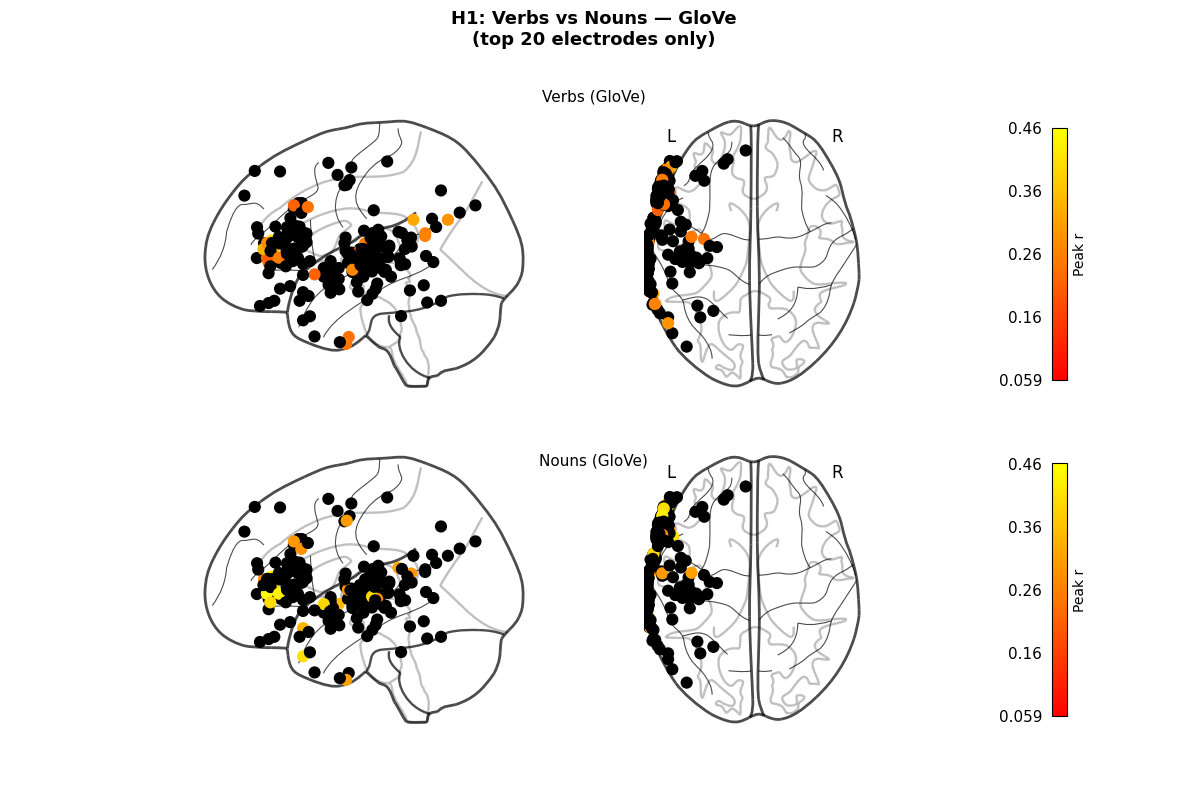

Saved: new_hypothesis_correlations/brainplot_top20_glove_verbs_vs_glove_nouns.png



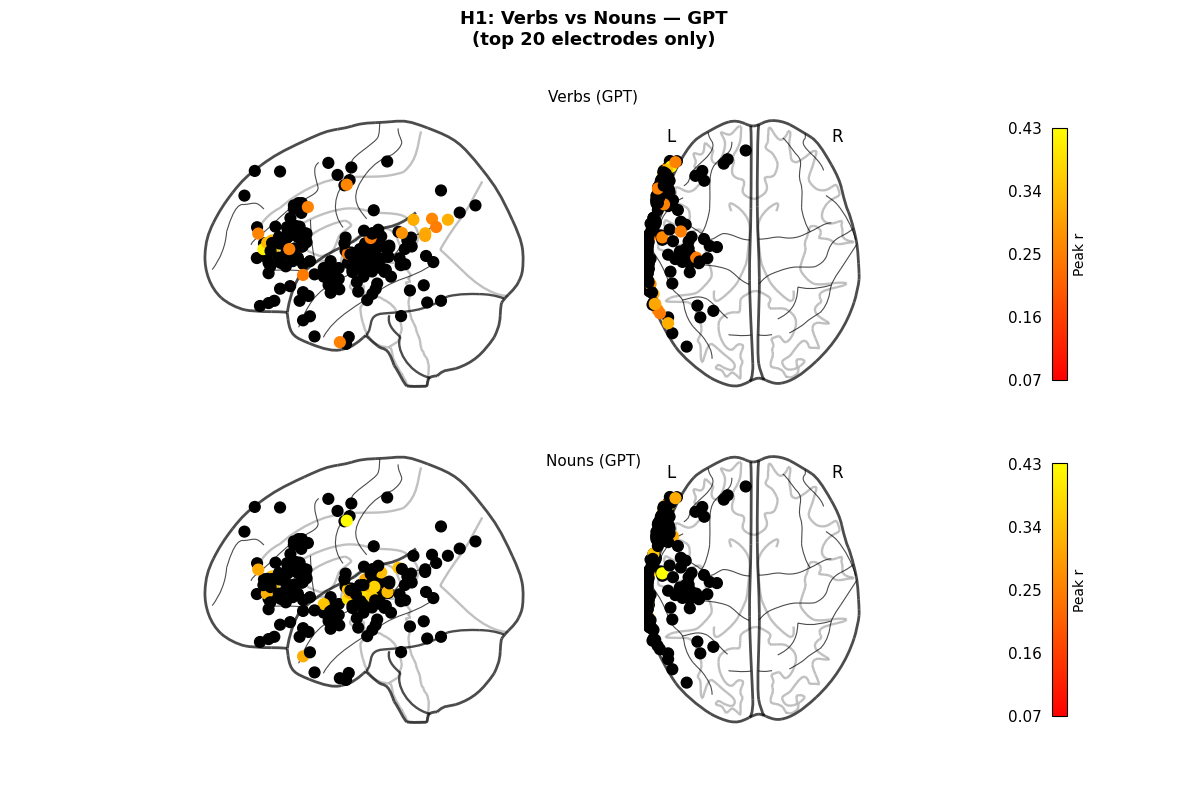

Saved: new_hypothesis_correlations/brainplot_top20_gpt_verbs_vs_gpt_nouns.png



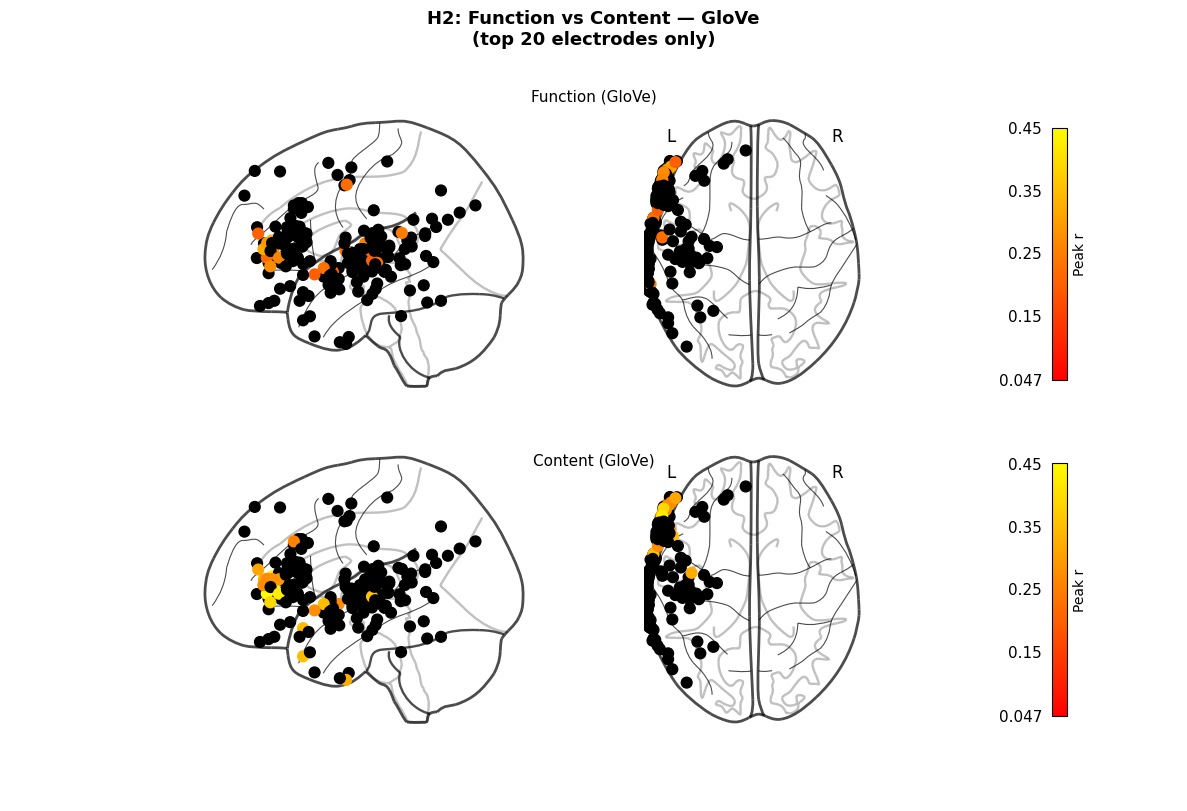

Saved: new_hypothesis_correlations/brainplot_top20_glove_function_vs_glove_content.png



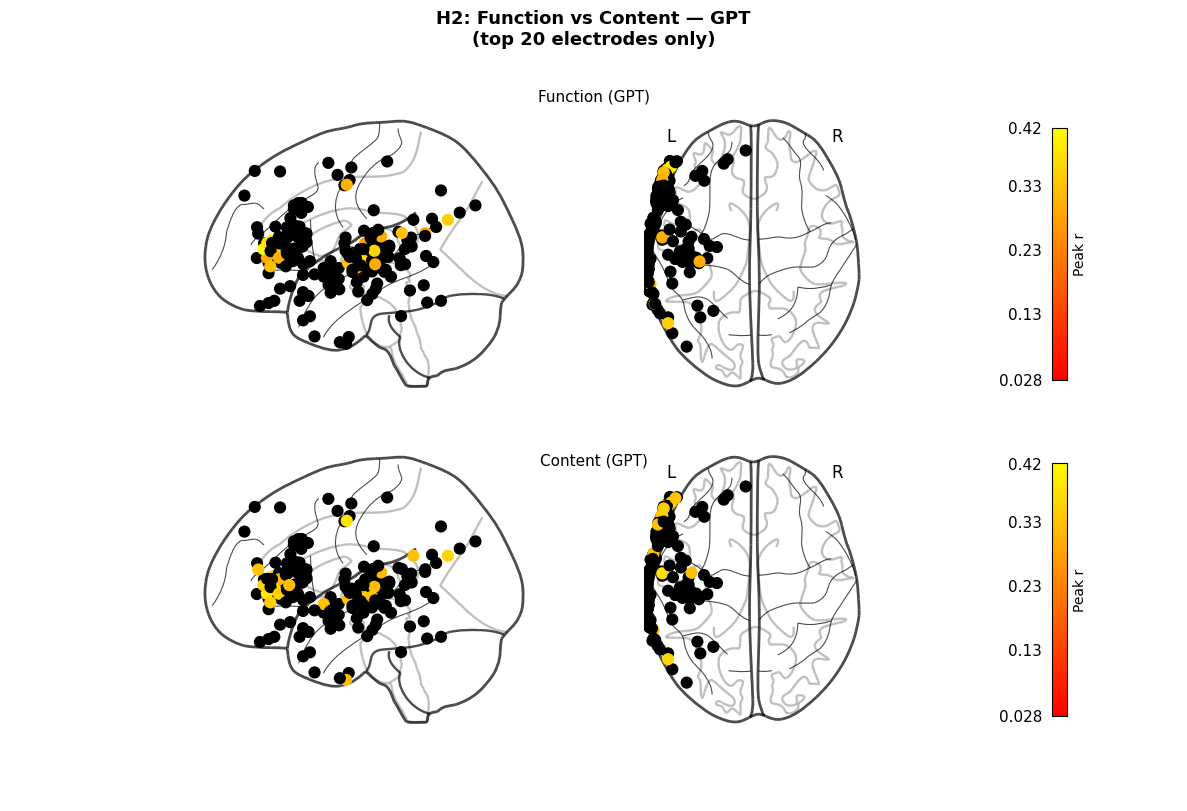

Saved: new_hypothesis_correlations/brainplot_top20_gpt_function_vs_gpt_content.png



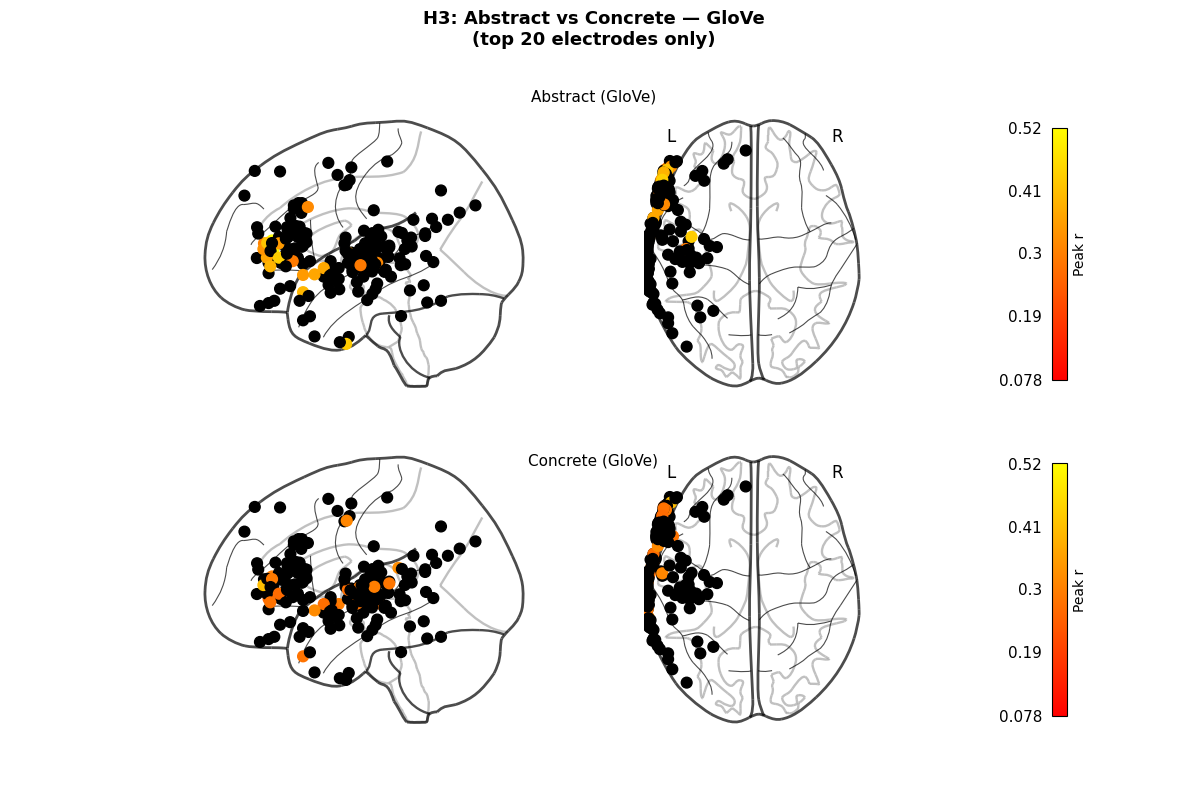

Saved: new_hypothesis_correlations/brainplot_top20_glove_abstract_vs_glove_concrete.png



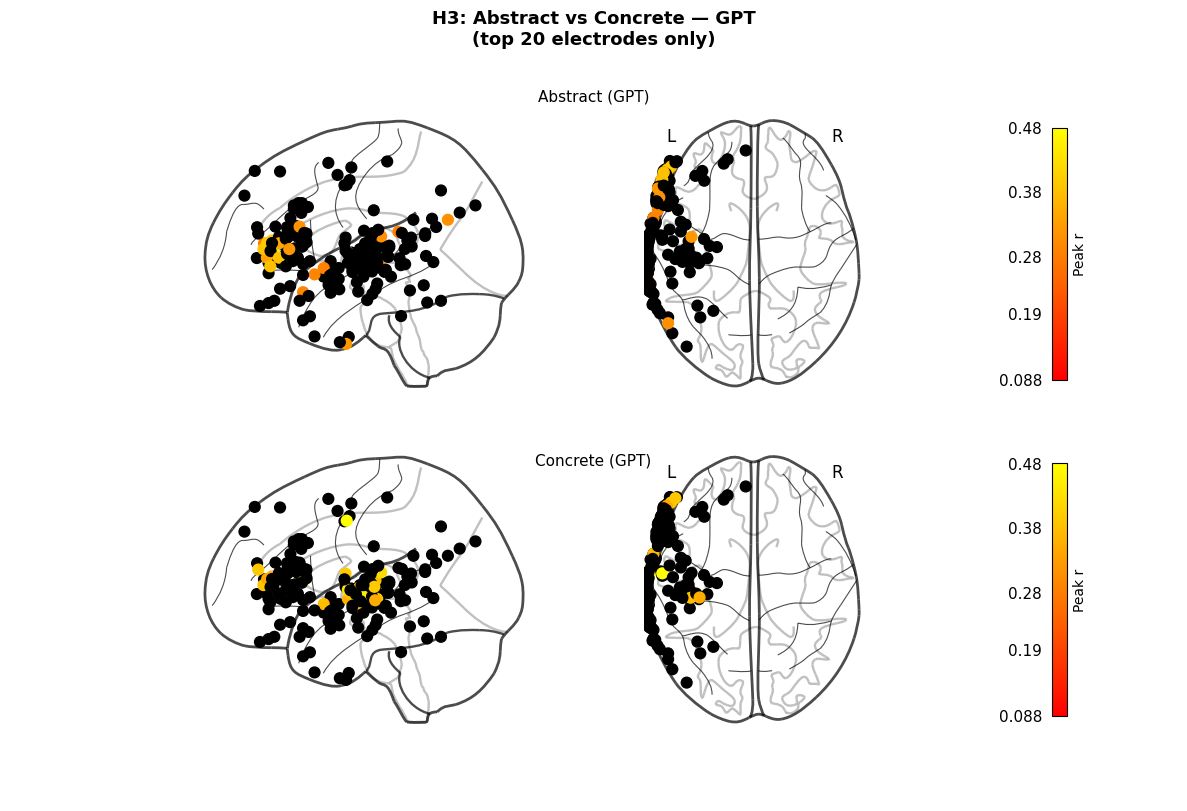

Saved: new_hypothesis_correlations/brainplot_top20_gpt_abstract_vs_gpt_concrete.png



In [ ]:
# =============================================================================
# Brain plots showing ONLY top-N electrodes 
# =============================================================================

TOP_SHOW = 20

def top_only(p_arr, n=TOP_SHOW):
    masked  = np.full(len(p_arr), np.nan)
    top_idx = np.argsort(p_arr)[::-1][:n]
    masked[top_idx] = p_arr[top_idx]
    return masked

PAIRS = [
    ("glove_verbs",    "glove_nouns",    "Verbs (GloVe)",    "Nouns (GloVe)",    "H1: Verbs vs Nouns — GloVe"),
    ("gpt_verbs",      "gpt_nouns",      "Verbs (GPT)",      "Nouns (GPT)",      "H1: Verbs vs Nouns — GPT"),
    ("glove_function", "glove_content",  "Function (GloVe)", "Content (GloVe)",  "H2: Function vs Content — GloVe"),
    ("gpt_function",   "gpt_content",    "Function (GPT)",   "Content (GPT)",    "H2: Function vs Content — GPT"),
    ("glove_abstract", "glove_concrete", "Abstract (GloVe)", "Concrete (GloVe)", "H3: Abstract vs Concrete — GloVe"),
    ("gpt_abstract",   "gpt_concrete",   "Abstract (GPT)",   "Concrete (GPT)",   "H3: Abstract vs Concrete — GPT"),
]

for cat_a, cat_b, lab_a, lab_b, suptitle in PAIRS:
    if cat_a not in peak_corrs or cat_b not in peak_corrs:
        print(f"Skipping {suptitle} — missing data")
        continue

    pa, pb = peak_corrs[cat_a], peak_corrs[cat_b]
    vmin   = min(pa.min(), pb.min())
    vmax   = max(pa.max(), pb.max())

    pa_masked = top_only(pa)
    pb_masked = top_only(pb)

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))
    fig.suptitle(f"{suptitle}\n(top {TOP_SHOW} electrodes only)",
                 fontsize=13, fontweight="bold", y=1.01)

    for ax, peak_arr, label in zip(axes, [pa_masked, pb_masked], [lab_a, lab_b]):
        display = plotting.plot_markers(
            peak_arr,
            all_coords,
            node_size=60,
            display_mode='lzr',   # ← fixed
            node_cmap='autumn',
            node_vmin=vmin,
            node_vmax=vmax,
            colorbar=True,
            alpha=1.0,
            axes=ax
        )
        # Remove right hemisphere panel
        if 'r' in display.axes:
            display.axes['r'].ax.remove()
            del display.axes['r']

        if display._cbar is not None:
            display._cbar.set_label('Peak r', fontsize=10)
        ax.set_title(label, fontsize=11, pad=6)

    plt.tight_layout()
    save_name = f"new_hypothesis_correlations/brainplot_top{TOP_SHOW}_{cat_a}_vs_{cat_b}.png"
    plt.savefig(save_name, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}\n")

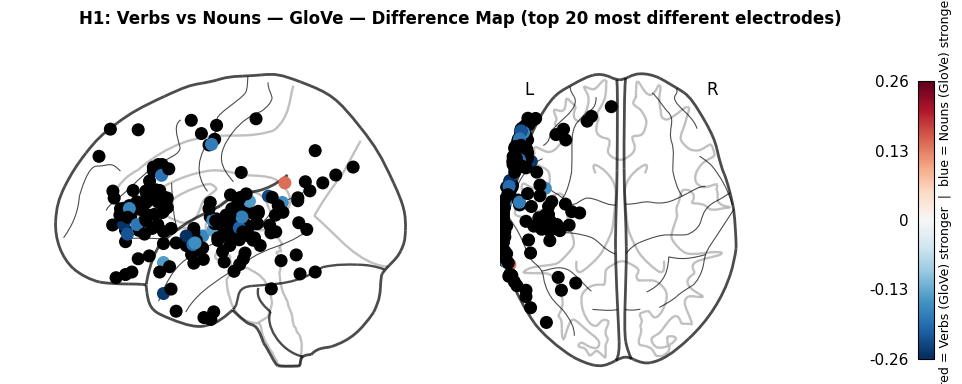

Saved: new_hypothesis_correlations/diffmap_top20_glove_verbs_vs_glove_nouns.png

  Top 5 electrodes where Verbs (GloVe) > Nouns (GloVe):
    Δr=+0.1423  LST7                (-68.0,-44.0,25.0)
    Δr=+0.1238  G77                 (-56.0,43.0,8.0)
    Δr=+0.1205  G20                 (-67.1,-50.9,17.1)
    Δr=+0.1077  O8                  (-66.8,-50.8,15.6)
    Δr=+0.1057  LGB86               (-61.0,40.0,0.0)

  Top 5 electrodes where Nouns (GloVe) > Verbs (GloVe):
    Δr=-0.2556  G119                (-68.0,8.0,-3.0)
    Δr=-0.2492  G17                 (-58.0,41.0,3.0)
    Δr=-0.2473  G63                 (-54.7,20.0,-33.3)
    Δr=-0.2305  G47                 (-71.3,-35.3,18.0)
    Δr=-0.2211  G92                 (-61.0,39.0,-2.0)



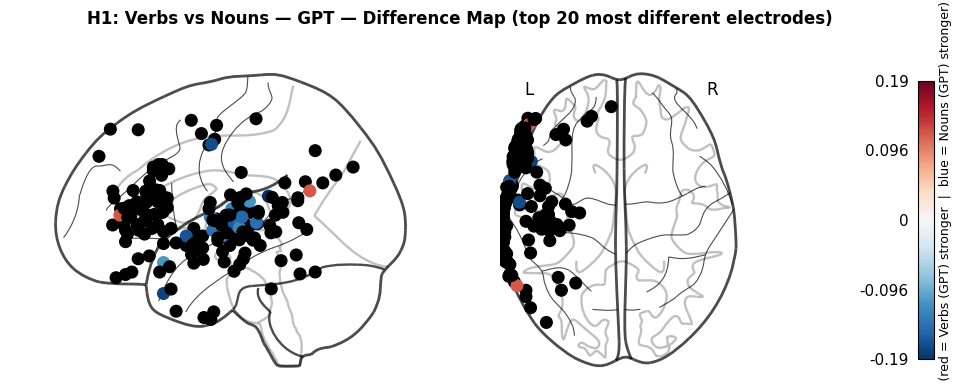

Saved: new_hypothesis_correlations/diffmap_top20_gpt_verbs_vs_gpt_nouns.png

  Top 5 electrodes where Verbs (GPT) > Nouns (GPT):
    Δr=+0.1202  G77                 (-56.0,43.0,8.0)
    Δr=+0.1176  O7                  (-63.6,-57.2,20.8)
    Δr=+0.0958  LST7                (-68.0,-44.0,25.0)
    Δr=+0.0877  O8                  (-66.8,-50.8,15.6)
    Δr=+0.0673  DPMT6               (-48.2,-22.1,-15.1)

  Top 5 electrodes where Nouns (GPT) > Verbs (GPT):
    Δr=-0.1927  G47                 (-71.3,-35.3,18.0)
    Δr=-0.1778  G63                 (-54.7,20.0,-33.3)
    Δr=-0.1711  G75                 (-62.0,-5.3,45.3)
    Δr=-0.1669  G119                (-68.0,8.0,-3.0)
    Δr=-0.1616  G103                (-73.3,-15.0,1.3)



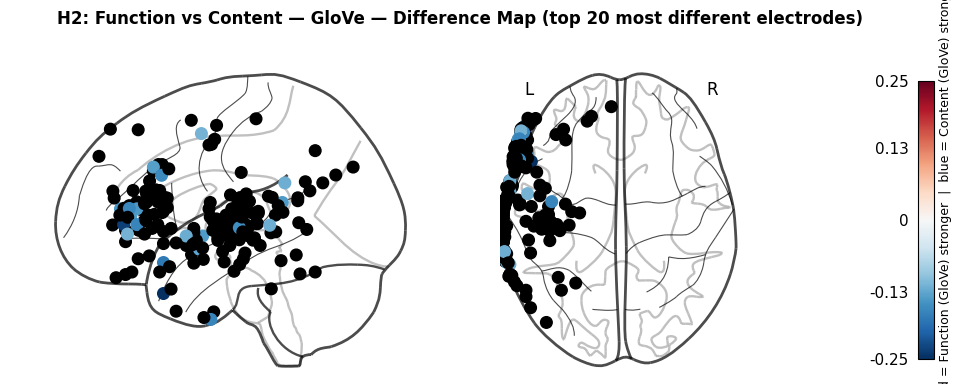

Saved: new_hypothesis_correlations/diffmap_top20_glove_function_vs_glove_content.png

  Top 5 electrodes where Function (GloVe) > Content (GloVe):
    Δr=+0.0938  G45                 (-72.7,-16.0,11.3)
    Δr=+0.0750  G56                 (-70.0,-37.3,17.3)
    Δr=+0.0689  LDSI9               (-44.0,-13.0,8.0)
    Δr=+0.0648  G110                (-71.3,-4.7,7.0)
    Δr=+0.0623  LGB121              (-73.0,-19.0,0.0)

  Top 5 electrodes where Content (GloVe) > Function (GloVe):
    Δr=-0.2503  G63                 (-54.7,20.0,-33.3)
    Δr=-0.2363  G17                 (-58.0,41.0,3.0)
    Δr=-0.1797  G54                 (-61.0,20.0,-17.0)
    Δr=-0.1658  AIT3                (-42.0,-5.0,-47.0)
    Δr=-0.1646  G93                 (-62.0,34.0,3.0)



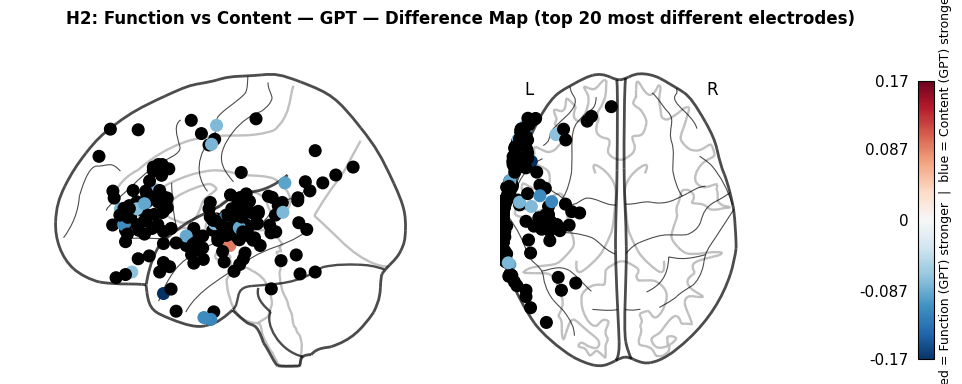

Saved: new_hypothesis_correlations/diffmap_top20_gpt_function_vs_gpt_content.png

  Top 5 electrodes where Function (GPT) > Content (GPT):
    Δr=+0.0900  LGA46               (-74.0,-15.0,-8.0)
    Δr=+0.0748  GA45                (-71.0,-6.0,6.0)
    Δr=+0.0669  G78                 (-58.8,40.8,11.6)
    Δr=+0.0659  G77                 (-56.0,43.0,8.0)
    Δr=+0.0573  G82                 (-61.3,27.3,26.0)

  Top 5 electrodes where Content (GPT) > Function (GPT):
    Δr=-0.1744  G63                 (-54.7,20.0,-33.3)
    Δr=-0.1132  AIT3                (-42.0,-5.0,-47.0)
    Δr=-0.1101  AIT4                (-49.3,-1.3,-46.0)
    Δr=-0.1100  G17                 (-58.0,41.0,3.0)
    Δr=-0.1007  G102                (-73.0,-12.7,6.7)



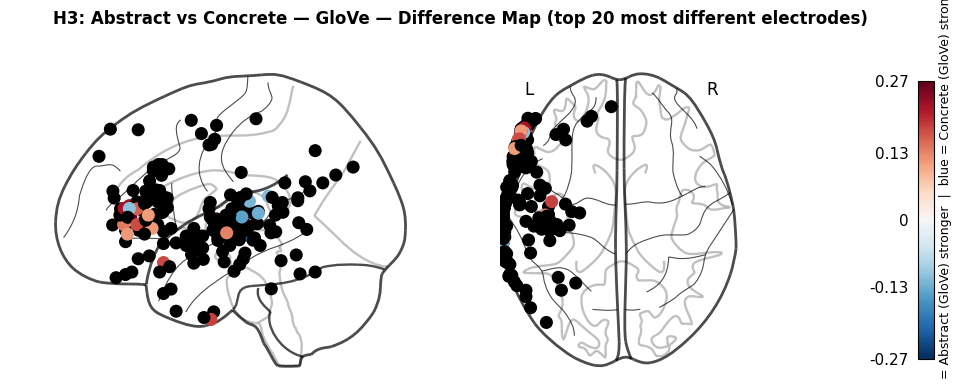

Saved: new_hypothesis_correlations/diffmap_top20_glove_abstract_vs_glove_concrete.png

  Top 5 electrodes where Abstract (GloVe) > Concrete (GloVe):
    Δr=+0.2652  LGB79               (-61.3,37.3,7.0)
    Δr=+0.2217  LGA10               (-59.0,38.0,13.0)
    Δr=+0.2213  G78                 (-58.8,40.8,11.6)
    Δr=+0.2183  GA45                (-71.0,-6.0,6.0)
    Δr=+0.1819  AIT3                (-42.0,-5.0,-47.0)

  Top 5 electrodes where Concrete (GloVe) > Abstract (GloVe):
    Δr=-0.1686  LGA47               (-74.0,-25.0,-3.0)
    Δr=-0.1466  LGA38               (-72.0,-11.3,2.7)
    Δr=-0.1420  G23                 (-71.3,-21.3,7.0)
    Δr=-0.1301  G55                 (-72.0,-30.0,9.0)
    Δr=-0.1204  G46                 (-72.0,-25.3,15.3)



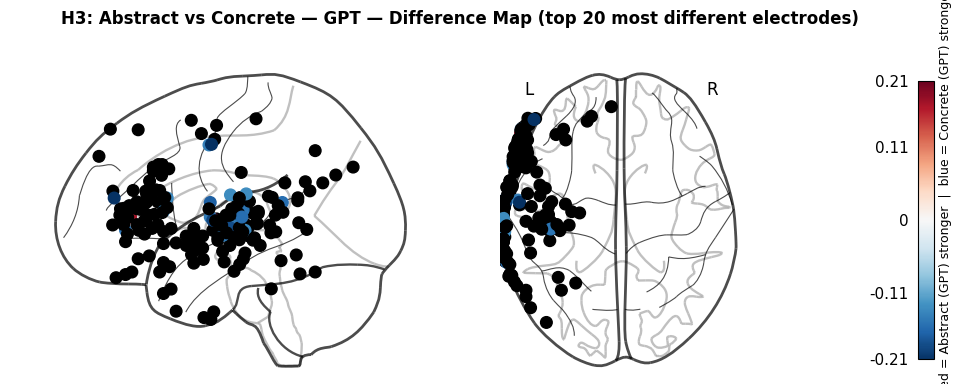

Saved: new_hypothesis_correlations/diffmap_top20_gpt_abstract_vs_gpt_concrete.png

  Top 5 electrodes where Abstract (GPT) > Concrete (GPT):
    Δr=+0.2035  GA45                (-71.0,-6.0,6.0)
    Δr=+0.1742  LGB79               (-61.3,37.3,7.0)
    Δr=+0.1155  LGB122              (-72.0,-25.0,2.0)
    Δr=+0.1123  G93                 (-62.0,34.0,3.0)
    Δr=+0.1009  G92                 (-61.0,39.0,-2.0)

  Top 5 electrodes where Concrete (GPT) > Abstract (GPT):
    Δr=-0.2127  G75                 (-62.0,-5.3,45.3)
    Δr=-0.2104  AF6                 (-53.0,46.0,17.0)
    Δr=-0.1951  G44                 (-70.7,-6.0,5.3)
    Δr=-0.1910  G103                (-73.3,-15.0,1.3)
    Δr=-0.1745  G32                 (-72.7,-4.7,14.7)



In [ ]:
# =============================================================================
#  Difference map 
# =============================================================================

TOP_DIFF = 20
CH_COL   = "ch_name"   # ← adjust if needed

for cat_a, cat_b, lab_a, lab_b, suptitle in PAIRS:
    if cat_a not in peak_corrs or cat_b not in peak_corrs:
        continue

    diff   = peak_corrs[cat_a] - peak_corrs[cat_b]
    absmax = np.abs(diff).max()

    top_diff_idx = np.argsort(np.abs(diff))[::-1][:TOP_DIFF]
    diff_masked  = np.full(len(diff), np.nan)
    diff_masked[top_diff_idx] = diff[top_diff_idx]

    fig, ax = plt.subplots(1, 1, figsize=(12, 4))

    display = plotting.plot_markers(
        diff_masked,
        all_coords,
        node_size=70,
        display_mode='lzr',   # ← fixed
        node_cmap='RdBu_r',
        node_vmin=-absmax,
        node_vmax= absmax,
        colorbar=True,
        alpha=1.0,
        axes=ax
    )
    if 'r' in display.axes:
        display.axes['r'].ax.remove()
        del display.axes['r']

    if display._cbar is not None:
        display._cbar.set_label(
            f'Δ Peak r  (red = {lab_a} stronger  |  blue = {lab_b} stronger)',
            fontsize=9)

    fig.suptitle(
        f"{suptitle} — Difference Map (top {TOP_DIFF} most different electrodes)",
        fontsize=12, fontweight="bold", y=1.02
    )

    save_name = f"new_hypothesis_correlations/diffmap_top{TOP_DIFF}_{cat_a}_vs_{cat_b}.png"
    plt.savefig(save_name, dpi=200, bbox_inches='tight')
    plt.show()
    print(f"Saved: {save_name}")

    # Print electrode names for the most differentiated sites
    top_pos = np.argsort(diff)[::-1][:5]
    top_neg = np.argsort(diff)[:5]

    print(f"\n  Top 5 electrodes where {lab_a} > {lab_b}:")
    for i in top_pos:
        row  = sig_elec_master.iloc[i]
        name = row[CH_COL] if CH_COL in sig_elec_master.columns \
               else f"sub{row['subject']}_e{int(row['elec_idx'])}"
        x, y, z = all_coords[i]
        print(f"    Δr={diff[i]:+.4f}  {str(name):<18}  ({x:.1f},{y:.1f},{z:.1f})")

    print(f"\n  Top 5 electrodes where {lab_b} > {lab_a}:")
    for i in top_neg:
        row  = sig_elec_master.iloc[i]
        name = row[CH_COL] if CH_COL in sig_elec_master.columns \
               else f"sub{row['subject']}_e{int(row['elec_idx'])}"
        x, y, z = all_coords[i]
        print(f"    Δr={diff[i]:+.4f}  {str(name):<18}  ({x:.1f},{y:.1f},{z:.1f})")
    print()

# Hypothesis 2: Incorrect words split by semantic distance

## Creating the Semantic Distance Groups

In [65]:
#Re-loading just to be safe (previous cells dont influence it)
#Also ensures that df_gpt_glove has just the glove embedding (NOT the gpt ones)
transcript_gpt_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_gpt_path, sep="\t", index_col=0)

# One row per word (take first token for multi-token words)
df_gpt = (df_gpt
          .groupby('word_idx', sort=True)
          .first()
          .reset_index())

df_gpt["word_clean"] = df_gpt["word"].apply(clean_word)

# Filter to words that have GloVe embeddings (same set used throughout)
embeddings, valid_indices = [], []
for idx, row in df_gpt.iterrows():
    w = row["word_clean"]
    if w not in EXCLUDE_FILLERS and w in glove_model:
        embeddings.append(glove_model[w])
        valid_indices.append(idx)

df_gpt_glove = df_gpt.loc[valid_indices].copy()
df_gpt_glove["glove_embedding"] = embeddings


In [66]:
df_gpt_glove

,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,word_clean,glove_embedding
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
...,...,...,...,...,...,...,...,...,...,...,...,...
5131,5131,go,1798.546,1798.646,Ġgo,467,20,0.008662,651,5.197536,go,"[0.14828, 0.17761, 0.42346, -0.31489, 0.32273,..."
5132,5132,to,1798.666,1798.746,Ġto,284,0,0.202626,284,3.946364,to,"[0.68047, -0.039263, 0.30186, -0.17792, 0.4296..."
5133,5133,court,1798.786,1799.006,Ġcourt,2184,99,0.000510,257,3.669363,court,"[-0.35445, -0.55181, -1.024, 0.59384, 0.57911,..."
5134,5134,over,1799.046,1799.226,Ġover,625,4,0.062957,284,3.113599,over,"[0.12972, 0.088073, 0.24375, 0.078102, -0.1278..."


In [ ]:
# Build correct / incorrect word sets based on paper ranking
# 'rank' = rank of the actual word in GPT-2's top-k distribution
# rank <= 4  → correctly predicted (top-5)
# rank  > 4  → incorrectly predicted

correct   = df_gpt_glove[df_gpt_glove['rank'] <= 4].copy()
incorrect = df_gpt_glove[df_gpt_glove['rank']  > 4].copy()

# For incorrect words, we also need the GloVe embedding of GPT-2's TOP-1 prediction
tokenizer = GPT2Tokenizer.from_pretrained('gpt2-xl')

def id_to_word(token_id):
    return tokenizer.decode([token_id]).strip()

incorrect = incorrect.copy()
incorrect['top_pred'] = incorrect['top_pred'].apply(id_to_word)
incorrect['top_pred'] = incorrect['top_pred'].apply(clean_word)

# Keep only incorrect words where the predicted word has a GloVe embeddings
pred_embeddings, valid_pred_indices = [], []
for idx, row in incorrect.iterrows():
    w_pred = row['top_pred']
    if w_pred not in EXCLUDE_FILLERS and w_pred in glove_model:
        pred_embeddings.append(glove_model[w_pred])
        valid_pred_indices.append(idx)

incorrect_filtered = incorrect.loc[valid_pred_indices].copy()
incorrect_filtered['glove_embedding_prediction'] = pred_embeddings

# Same as other notebooks and produces the same numbers
print(f"Correct words    : {len(correct)}")
print(f"Incorrect words  : {len(incorrect_filtered)} (after pred-GloVe filter)")

# Embedding matrices for Fig 4B-style analysis
X_glove_correct       = np.stack(correct['glove_embedding'].values).astype('float32')
X_glove_perceived_red = np.stack(incorrect_filtered['glove_embedding'].values).astype('float32')
X_glove_prediction    = np.stack(incorrect_filtered['glove_embedding_prediction'].values).astype('float32')

Correct words    : 2531
Incorrect words  : 1978 (after pred-GloVe filter)


In [52]:
correct.shape

(2531, 12)

In [50]:
incorrect_filtered.shape

(1978, 13)

In [ ]:
#Now that we have correct and incorrect
##Correct, will act as our baseline, it will be the same as figure 4b (to compare it to/blue line)

##Incorrect, will be split into two: the perceived word and the predicted word (
#Each of these incorrect catergories we are then going to be split into 3: far away distance, medium distance, and close to the actual word that was said

#This is were our results will be saved/other correlations
RESULTS_DIR_P2 = "new_hypothesis_PART_2"
os.makedirs(RESULTS_DIR_P2, exist_ok=True)
print(f"Output folder ready: {RESULTS_DIR_P2}/")

# =============================================================================
#  Compute cosine distances 
# =============================================================================

def cosine_distance(v1, v2):
    denom = np.linalg.norm(v1) * np.linalg.norm(v2)
    if denom == 0:
        return np.nan
    return 1.0 - np.dot(v1, v2) / denom

distances = [
    cosine_distance(
        # Compute cosine distance between perceived and predicted embeddings
        np.array(row['glove_embedding']),
        np.array(row['glove_embedding_prediction'])
    )
    for _, row in incorrect_filtered.iterrows()
]

incorrect_filtered = incorrect_filtered.copy()
#creates a copy of the incorrect dataframe and loops through each row calculated this cosine distnace between the glove embedding
# the stores that distance in the new column: "cosine_dist" 
incorrect_filtered['cosine_dist'] = distances
#safety: in case the distance failed will be NA and row droped (none of it failed because the size is the same)
incorrect_filtered = incorrect_filtered.dropna(subset=['cosine_dist'])

print("Cosine distance statistics (predicted vs perceived, GloVe):")
print(incorrect_filtered['cosine_dist'].describe().round(3)) #gives stastics about the cosine distances, such as mean, std, min, max, etc.


Output folder ready: new_hypothesis_PART_2/
Cosine distance statistics (predicted vs perceived, GloVe):
count    1978.000
mean        0.431
std         0.256
min        -0.000
25%         0.224
50%         0.376
75%         0.584
max         1.329
Name: cosine_dist, dtype: float64


In [68]:
incorrect_filtered.shape

(1978, 14)

In [ ]:
# =============================================================================
# — Tertile split (3 equal-size groups — fairest approach)
#
# Why tertiles and not fixed thresholds?
#   Fixed thresholds (e.g. <0.2, 0.2-0.6, >0.6) can produce very unequal
#   group sizes because the cosine distance distribution is right-skewed
#   (see histogram). Equal-size groups mean the encoding model sees the
#   same number of words in each condition, making the correlation estimates
#   directly comparable without worrying about power differences.
# =============================================================================

t33 = incorrect_filtered['cosine_dist'].quantile(1/3)
t67 = incorrect_filtered['cosine_dist'].quantile(2/3)

df_close   = incorrect_filtered[incorrect_filtered['cosine_dist'] <= t33].copy()
df_medium  = incorrect_filtered[(incorrect_filtered['cosine_dist'] > t33) &
                                 (incorrect_filtered['cosine_dist'] <= t67)].copy()
df_far     = incorrect_filtered[incorrect_filtered['cosine_dist'] > t67].copy()

print(f"Tertile thresholds  : 33rd = {t33:.3f}  |  67th = {t67:.3f}")
print(f"Close   (dist ≤ {t33:.3f}) : {len(df_close):>5} words  "
      f"mean dist = {df_close['cosine_dist'].mean():.3f}")
print(f"Medium  ({t33:.3f} < dist ≤ {t67:.3f}) : {len(df_medium):>5} words  "
      f"mean dist = {df_medium['cosine_dist'].mean():.3f}")
print(f"Far     (dist  > {t67:.3f}) : {len(df_far):>5} words  "
      f"mean dist = {df_far['cosine_dist'].mean():.3f}")

Tertile thresholds  : 33rd = 0.273  |  67th = 0.514
Close   (dist ≤ 0.273) :   660 words  mean dist = 0.179
Medium  (0.273 < dist ≤ 0.514) :   659 words  mean dist = 0.384
Far     (dist  > 0.514) :   659 words  mean dist = 0.729


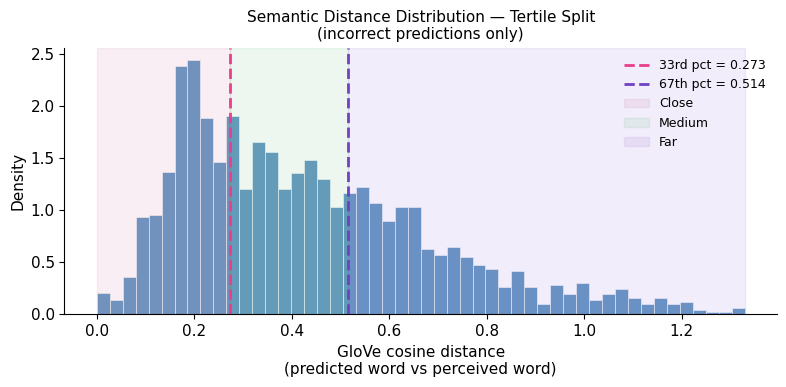

Saved histogram.


In [107]:
# =============================================================================
# Distribution plot with tertile lines
# =============================================================================

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(incorrect_filtered['cosine_dist'], bins=50, color='steelblue',
        edgecolor='white', linewidth=0.5, density=True, alpha=0.8)

ax.axvline(t33, color='#E83E8C', lw=2, ls='--', label=f'33rd pct = {t33:.3f}')
ax.axvline(t67, color='#6F42C1', lw=2, ls='--', label=f'67th pct = {t67:.3f}')

# Shade the three regions
ymax = ax.get_ylim()[1]
ax.axvspan(incorrect_filtered['cosine_dist'].min(), t33,
           alpha=0.08, color="#BA3271", label='Close')
ax.axvspan(t33, t67, alpha=0.08, color="#1BA244", label='Medium')
ax.axvspan(t67, incorrect_filtered['cosine_dist'].max(),
           alpha=0.08, color="#5D25C5", label='Far')

ax.set_xlabel('GloVe cosine distance\n(predicted word vs perceived word)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Semantic Distance Distribution — Tertile Split\n'
             '(incorrect predictions only)', fontsize=11)
ax.legend(frameon=False, fontsize=9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR_P2}/Figure_P2_SemDist_histogram_tertiles.png',
            dpi=400, bbox_inches='tight')
plt.show()
print("Saved histogram.")

#Can clearly see the right skewed distribution and the tertile splits in the histogram

In [ ]:
# =============================================================================
# Build embedding matrices for all conditions
# =============================================================================

def make_X_pair(df_sub):
    """Return (X_perceived, X_predicted) for a subset of incorrect_filtered."""
    X_perc = np.stack(df_sub['glove_embedding'].values).astype('float32')
    X_pred = np.stack(df_sub['glove_embedding_prediction'].values).astype('float32')
    return X_perc, X_pred

X_close_perc,  X_close_pred  = make_X_pair(df_close)
X_medium_perc, X_medium_pred = make_X_pair(df_medium)
X_far_perc,    X_far_pred    = make_X_pair(df_far)
X_correct                    = np.stack(correct['glove_embedding'].values).astype('float32')

# All 7 conditions
CONDITIONS_P2 = [
    # (save_key,            df_words,  X_embedding)
    ('correct_baseline',    correct,   X_correct),
    ('close_prediction',    df_close,  X_close_pred),
    ('close_perceived',     df_close,  X_close_perc),
    ('medium_prediction',   df_medium, X_medium_pred),
    ('medium_perceived',    df_medium, X_medium_perc),
    ('far_prediction',      df_far,    X_far_pred),
    ('far_perceived',       df_far,    X_far_perc),
]

print("Condition sizes:")
for key, df_c, X_c in CONDITIONS_P2:
    print(f"  {key:<25} n={len(df_c):>5}  X={X_c.shape}")

Condition sizes:
  correct_baseline          n= 2531  X=(2531, 50)
  close_prediction          n=  660  X=(660, 50)
  close_perceived           n=  660  X=(660, 50)
  medium_prediction         n=  659  X=(659, 50)
  medium_perceived          n=  659  X=(659, 50)
  far_prediction            n=  659  X=(659, 50)
  far_perceived             n=  659  X=(659, 50)


## Running Encoding Model

In [ ]:
# =============================================================================
#  Encoding runner (same pipeline as previous code)
# =============================================================================

subject_ids     = ["02", "03", "04", "05", "06", "07", "08", "09"]
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

lags_ms     = np.linspace(-2000, 2000, 161)
alphas      = np.logspace(1, 10, 10)
inner_cv    = KFold(n_splits=5, shuffle=False)
model       = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)

#re-defining the same encoding model just to be safe
def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)


def run_encoding_p2(cond_key, df_cond, X_cond, save_dir=RESULTS_DIR_P2):
    """
    Run the encoding model for one condition across all subjects.
    Returns array of shape (total_sig_elec_across_subs, 161).
    """
    all_corrs = []

    for sid in subject_ids:
        sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
        if len(sub_sig) == 0:
            print(f"  sub-{sid}: no significant electrodes, skipping")
            continue

        sig_indices = sub_sig["elec_idx"].values

        #Load raw, pick LH significant electrodes 
        file_path = BIDSPath(
            root=f"{bids_root}derivatives/ecogprep",
            subject=sid, task="podcast", datatype="ieeg",
            description="highgamma", suffix="ieeg", extension=".fif"
        )
        raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

        ch2loc      = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
        coords_mm   = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
        lh_mask     = coords_mm[:, 0] < 0
        lh_ch_names = [ch for ch, keep in zip(raw.ch_names, lh_mask) if keep]
        raw         = raw.copy().pick(lh_ch_names)
        sig_ch_names = [raw.ch_names[i] for i in sig_indices]
        raw          = raw.copy().pick(sig_ch_names)

        # Build epochs for this condition's word onsets 
        sfreq  = raw.info['sfreq']
        events = np.zeros((len(df_cond), 3), dtype=int)
        events[:, 0] = (df_cond['start'].values * sfreq).astype(int)

        epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                            baseline=None, proj=False, event_id=None,
                            preload=True, event_repeated="merge")

        # ── Window averaging → (n_words_kept, n_sig_elec, 161) ───────────
        times       = epochs.times
        lag_centers = np.arange(-2.0, 2.0 + 0.025 / 2, 0.025)
        WIN_HALF    = 0.100
        lag_masks   = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                       for τ in lag_centers]

        epochs_data                 = epochs.get_data(copy=True)
        n_words_kept, n_sig_elec, _ = epochs_data.shape
        epochs_shape                = (n_sig_elec, 161)

        epochs_windowed = np.stack(
            [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
        ).astype(np.float32)

        Y = epochs_windowed.reshape(n_words_kept, n_sig_elec * 161)
        if "torch" in get_backend().__name__:
            Y = Y.astype(np.float32)

        # ── Align embeddings to epochs actually kept ───────────────────────
        X_sel = X_cond[epochs.selection].astype("float32")

        print(f"  sub-{sid}: {n_sig_elec} elec | {n_words_kept} words kept "
              f"(from {len(df_cond)}) | X={X_sel.shape}")

        corrs = train_encoding(X_sel, Y, epochs_shape)   # (10, n_sig_elec, 161)

        fname = os.path.join(save_dir, f"corrs_{cond_key}_{sid}.npy")
        np.save(fname, corrs)

        all_corrs.append(corrs.mean(axis=0))   # (n_sig_elec, 161) — average folds

    combined = np.concatenate(all_corrs, axis=0)   # (total_elec, 161)
    print(f"  → {cond_key}: final shape {combined.shape}")
    return combined

In [ ]:
# =============================================================================
#  — Run all 7 conditions (save each time)
# =============================================================================

results_p2 = {}

for cond_key, df_cond, X_cond in CONDITIONS_P2:
    print(f"\n{'='*60}")
    print(f"Condition: {cond_key}  ({len(df_cond)} words,  emb dim {X_cond.shape[1]})")
    print('='*60)
    results_p2[cond_key] = run_encoding_p2(cond_key, df_cond, X_cond)

print("\n✓ All Part-2 encodings complete.")


Condition: correct_baseline  (2531 words,  emb dim 50)
  sub-02: no significant electrodes, skipping
  sub-03: 41 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-04: 15 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-05: 3 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-06: 25 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-07: 19 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-08: 16 elec | 2528 words kept (from 2531) | X=(2528, 50)
  sub-09: 55 elec | 2528 words kept (from 2531) | X=(2528, 50)
  → correct_baseline: final shape (174, 161)

Condition: close_prediction  (660 words,  emb dim 50)
  sub-02: no significant electrodes, skipping
  sub-03: 41 elec | 658 words kept (from 660) | X=(658, 50)
  sub-04: 15 elec | 658 words kept (from 660) | X=(658, 50)
  sub-05: 3 elec | 658 words kept (from 660) | X=(658, 50)
  sub-06: 25 elec | 658 words kept (from 660) | X=(658, 50)
  sub-07: 19 elec | 658 words kept (from 660) | X=(658, 50)
  sub-08: 16 

In [ ]:
# =============================================================================
#  — Re-load from disk (run this if you restart the kernel)
# =============================================================================

def reload_p2(cond_key, save_dir=RESULTS_DIR_P2):
    arrays = []
    for sid in subject_ids:
        fpath = os.path.join(save_dir, f"corrs_{cond_key}_{sid}.npy")
        if os.path.exists(fpath):
            arr = np.load(fpath)          # (n_folds, n_sig_elec, 161)
            arrays.append(arr.mean(axis=0))
    return np.concatenate(arrays, axis=0) if arrays else None

results_p2 = {key: reload_p2(key) for key, _, _ in CONDITIONS_P2}
print({k: v.shape for k, v in results_p2.items() if v is not None})

{'correct_baseline': (174, 161), 'close_prediction': (174, 161), 'close_perceived': (174, 161), 'medium_prediction': (174, 161), 'medium_perceived': (174, 161), 'far_prediction': (174, 161), 'far_perceived': (174, 161)}


Close-pred  > Medium-pred                    :  41 significant lags (FDR p<0.05)
Close-pred  > Far-pred                       :  36 significant lags (FDR p<0.05)
Medium-pred > Far-pred                       :   0 significant lags (FDR p<0.05)
Far-perc    > Medium-perc                    :  29 significant lags (FDR p<0.05)
Far-perc    > Close-perc                     :  41 significant lags (FDR p<0.05)
Medium-perc > Close-perc                     :  15 significant lags (FDR p<0.05)
Close-perc  > Close-pred                     :   4 significant lags (FDR p<0.05)
Medium-perc > Medium-pred                    :  51 significant lags (FDR p<0.05)
Far-perc    > Far-pred                       :  45 significant lags (FDR p<0.05)

✓ Significance testing complete.


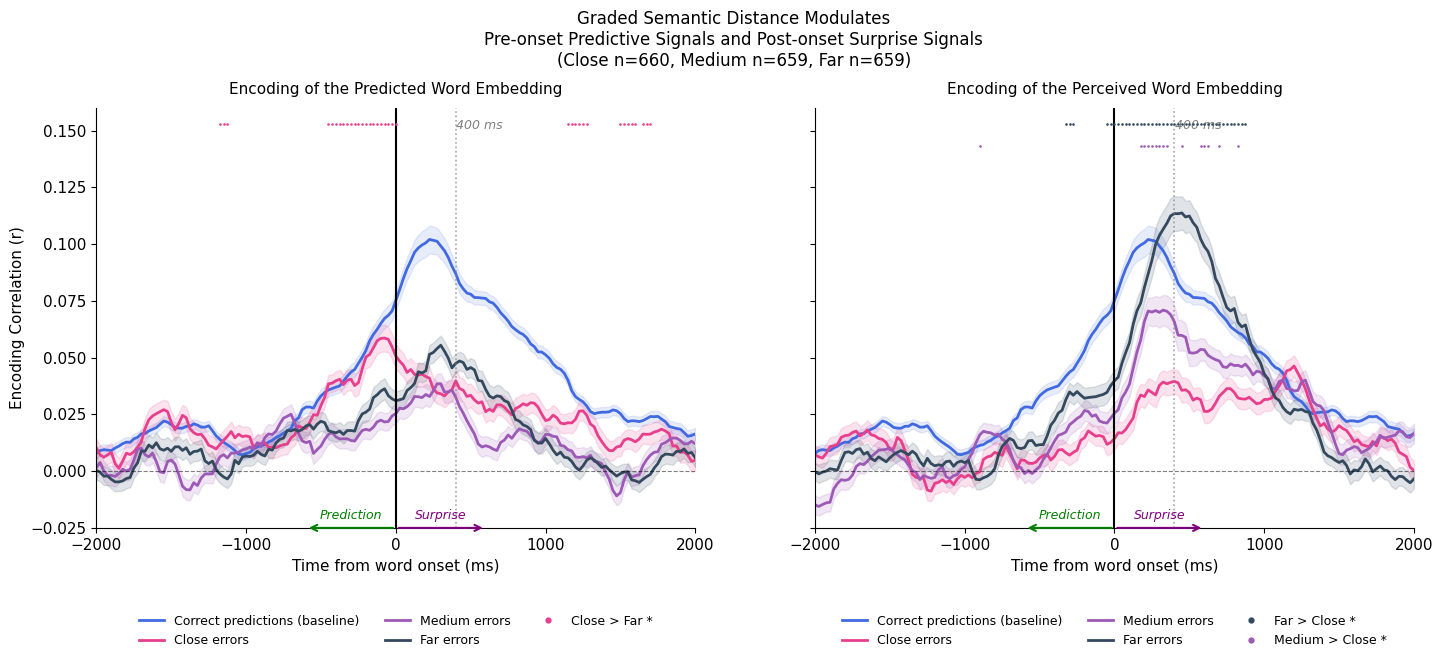

Saved: Figure_P2_GradedDistance_main.png / .pdf


In [120]:
###################### FINAL PLOTTING ###########

# =============================================================================
#  — Significance testing (sign-flip permutation + FDR)
# =============================================================================

# =============================================================================
#  — Significance testing (sign-flip permutation + FDR)
#
# Key comparisons:
#   PRE-ONSET (prediction encoding):
#     close_pred > medium_pred  → prediction content should be equally encoded
#     close_pred > far_pred       regardless of how wrong you were (flat pre-onset)
#   POST-ONSET (perceived encoding):
#     far_perc > medium_perc    → larger mismatch = larger surprise signal
#     far_perc > close_perc
#     medium_perc > close_perc
# =============================================================================

def permutation_test_p2(r_a, r_b, N_PERMS=5000, seed=0, fdr_alpha=0.05,
                         majority_thresh=0.60):
    """
    Sign-flip permutation test: does r_a > r_b at each lag?
    Returns boolean array of shape (161,).
    """
    n = min(r_a.shape[0], r_b.shape[0])
    r_a, r_b    = r_a[:n], r_b[:n]
    diff        = r_a - r_b
    actual_mean = diff.mean(axis=0)
    pct_pos     = (diff > 0).mean(axis=0)

    rng   = np.random.default_rng(seed=seed)
    signs = rng.choice(np.array([-1, 1], dtype=np.float32),
                       size=(N_PERMS, n, 1))
    null  = (signs * diff[np.newaxis]).mean(axis=1)

    p_vals     = np.array([(null[:, t] >= actual_mean[t]).mean()
                            for t in range(len(lags_ms))])
    sig_fdr, _ = fdrcorrection(p_vals, alpha=fdr_alpha)
    return sig_fdr & (pct_pos >= majority_thresh)


sig_p2 = {}
test_pairs = [
    # Pre-onset: prediction embedding comparisons
    ('close_prediction',  'medium_prediction', 'Close-pred  > Medium-pred'),
    ('close_prediction',  'far_prediction',    'Close-pred  > Far-pred'),
    ('medium_prediction', 'far_prediction',    'Medium-pred > Far-pred'),
    # Post-onset: perceived embedding comparisons (graded surprise)
    ('far_perceived',     'medium_perceived',  'Far-perc    > Medium-perc'),
    ('far_perceived',     'close_perceived',   'Far-perc    > Close-perc'),
    ('medium_perceived',  'close_perceived',   'Medium-perc > Close-perc'),
    # Prediction → perceived switch within each group
    ('close_perceived',   'close_prediction',  'Close-perc  > Close-pred'),
    ('medium_perceived',  'medium_prediction', 'Medium-perc > Medium-pred'),
    ('far_perceived',     'far_prediction',    'Far-perc    > Far-pred'),
]

for kA, kB, label in test_pairs:
    key         = f"{kA}_vs_{kB}"
    sig_p2[key] = permutation_test_p2(results_p2[kA], results_p2[kB])
    n_sig       = sig_p2[key].sum()
    print(f"{label:45s}: {n_sig:>3} significant lags (FDR p<0.05)")

print("\n✓ Significance testing complete.")


# =============================================================================
#  — Main figure: 2-panel plot with 3 groups
# =============================================================================

def get_mean_se(key):
    r = results_p2[key]
    return r.mean(axis=0), r.std(axis=0) / np.sqrt(r.shape[0])

C_CLOSE   = '#E83E8C'
C_MEDIUM  = '#9C59B6'
C_FAR     = '#34495E'
C_CORRECT = 'royalblue'

m_correct, se_correct = get_mean_se('correct_baseline')

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11})

fig, (ax_pred, ax_perc) = plt.subplots(1, 2, figsize=(17, 7), sharey=True)
fig.subplots_adjust(bottom=0.28)

y_min  = -0.025
y_max  =  0.160
# Only 2 rows needed now — one per plotted comparison per panel
star_y = [0.153, 0.143]

# ── Shared baseline ────────────────────────────────────────────────────────────
for ax in (ax_pred, ax_perc):
    ax.fill_between(lags_ms,
                    m_correct - se_correct, m_correct + se_correct,
                    color=C_CORRECT, alpha=0.12)
    ax.plot(lags_ms, m_correct, color=C_CORRECT, lw=2)

# ── LEFT PANEL: predicted word embedding ──────────────────────────────────────
ax = ax_pred

pred_handles = [
    plt.Line2D([0], [0], color=C_CORRECT, lw=2,
               label='Correct predictions (baseline)')
]

for key, col, lab in [
    ('close_prediction',  C_CLOSE,  'Close errors'),
    ('medium_prediction', C_MEDIUM, 'Medium errors'),
    ('far_prediction',    C_FAR,    'Far errors'),
]:
    m, s = get_mean_se(key)
    ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.15)
    ax.plot(lags_ms, m, color=col, lw=2)
    pred_handles.append(plt.Line2D([0], [0], color=col, lw=2, label=lab))

# Only the two theoretically important comparisons — Close>Far and Medium>Far
for sig_key, y_pos, color, label in [
    ('close_prediction_vs_far_prediction',  star_y[0], C_CLOSE,  'Close > Far *'),
    ('medium_prediction_vs_far_prediction', star_y[1], C_MEDIUM, 'Medium > Far *'),
]:
    sig = sig_p2.get(sig_key, np.zeros(161, bool))
    if sig.any():
        ax.scatter(lags_ms[sig], np.full(sig.sum(), y_pos),
                   marker='.', s=14, color=color, zorder=10, linewidths=0)
        pred_handles.append(
            plt.Line2D([0], [0], marker='.', color=color,
                       lw=0, markersize=7, label=label)
        )

ax.set_title('Encoding of the Predicted Word Embedding', fontsize=11, pad=10)
ax.set_xlabel('Time from word onset (ms)', fontsize=11)
ax.set_ylabel('Encoding Correlation (r)', fontsize=11)

ax.legend(handles=pred_handles,
          loc='upper center',
          bbox_to_anchor=(0.5, -0.18),
          frameon=False,
          fontsize=9,
          ncol=3)

# ── RIGHT PANEL: perceived word embedding ─────────────────────────────────────
ax = ax_perc

perc_handles = [
    plt.Line2D([0], [0], color=C_CORRECT, lw=2,
               label='Correct predictions (baseline)')
]

for key, col, lab in [
    ('close_perceived',  C_CLOSE,  'Close errors'),
    ('medium_perceived', C_MEDIUM, 'Medium errors'),
    ('far_perceived',    C_FAR,    'Far errors'),
]:
    m, s = get_mean_se(key)
    ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.15)
    ax.plot(lags_ms, m, color=col, lw=2)
    perc_handles.append(plt.Line2D([0], [0], color=col, lw=2, label=lab))

# Only the two theoretically important comparisons — Far>Close and Medium>Close
for sig_key, y_pos, color, label in [
    ('far_perceived_vs_close_perceived',    star_y[0], C_FAR,    'Far > Close *'),
    ('medium_perceived_vs_close_perceived', star_y[1], C_MEDIUM, 'Medium > Close *'),
]:
    sig = sig_p2.get(sig_key, np.zeros(161, bool))
    if sig.any():
        ax.scatter(lags_ms[sig], np.full(sig.sum(), y_pos),
                   marker='.', s=14, color=color, zorder=10, linewidths=0)
        perc_handles.append(
            plt.Line2D([0], [0], marker='.', color=color,
                       lw=0, markersize=7, label=label)
        )

ax.set_title('Encoding of the Perceived Word Embedding', fontsize=11, pad=10)
ax.set_xlabel('Time from word onset (ms)', fontsize=11)

ax.legend(handles=perc_handles,
          loc='upper center',
          bbox_to_anchor=(0.5, -0.18),
          frameon=False,
          fontsize=9,
          ncol=3)

# ── Shared styling ─────────────────────────────────────────────────────────────
for ax in (ax_pred, ax_perc):
    ax.axhline(0,   color='black', lw=0.8, ls='--', alpha=0.5)
    ax.axvline(0,   color='black', lw=1.5)
    ax.axvline(400, color='grey',  lw=1.2, ls=':', alpha=0.7)
    ax.text(402, y_max - 0.005, '400 ms',
            ha='left', va='top', fontsize=9, color='grey', style='italic')

    ax.annotate('', xy=(-600, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='green', lw=1.5))
    ax.text(-300, y_min + 0.004, 'Prediction', color='green',
            style='italic', ha='center', fontsize=9)
    ax.annotate('', xy=(600, y_min), xytext=(0, y_min),
                arrowprops=dict(arrowstyle='->', color='purple', lw=1.5))
    ax.text(300, y_min + 0.004, 'Surprise', color='purple',
            style='italic', ha='center', fontsize=9)

    ax.set_ylim(y_min, y_max)
    ax.set_xlim(-2000, 2000)
    ax.set_xticks([-2000, -1000, 0, 1000, 2000])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('data', y_min))

fig.suptitle(
    'Graded Semantic Distance Modulates\n'
    'Pre-onset Predictive Signals and Post-onset Surprise Signals\n'
    f'(Close n={len(df_close)}, Medium n={len(df_medium)}, Far n={len(df_far)})',
    fontsize=12, y=1.02
)

plt.savefig(f'{RESULTS_DIR_P2}/Figure_P2_GradedDistance_main.png',
            dpi=300, bbox_inches='tight')
plt.savefig(f'{RESULTS_DIR_P2}/Figure_P2_GradedDistance_main.pdf',
            format='pdf', bbox_inches='tight')
plt.show()
print("Saved: Figure_P2_GradedDistance_main.png / .pdf")

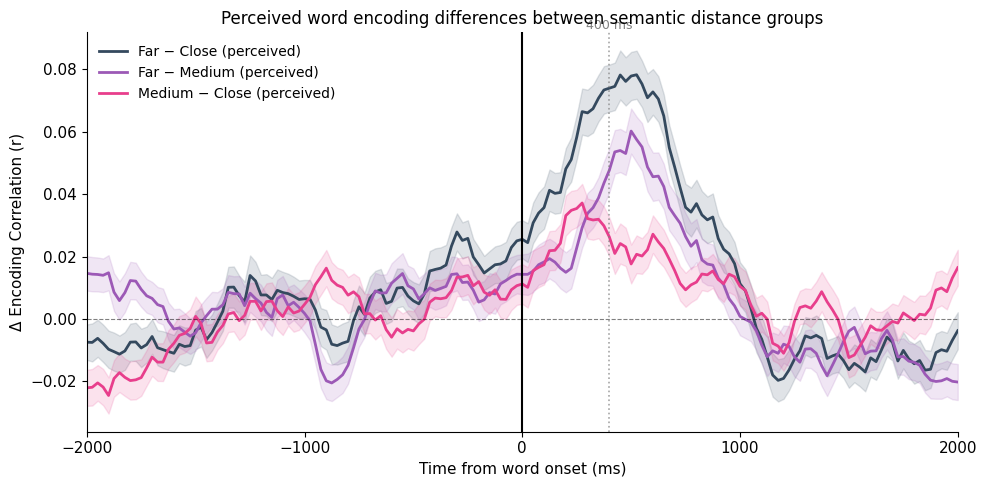

Saved: Figure_P2_perceived_diffcurves.png / .pdf


In [ ]:
# =============================================================================
#  Graded Post-onset Surprise Effect (perceived word)
# =============================================================================

n_common = min(results_p2[k].shape[0] for k in results_p2)

# Difference curves: perceived encoding
diff_far_vs_close  = (results_p2['far_perceived'][:n_common]
                      - results_p2['close_perceived'][:n_common])
diff_far_vs_medium = (results_p2['far_perceived'][:n_common]
                      - results_p2['medium_perceived'][:n_common])
diff_med_vs_close  = (results_p2['medium_perceived'][:n_common]
                      - results_p2['close_perceived'][:n_common])

fig, ax = plt.subplots(figsize=(10, 5))

for diff, col, lab in [
    (diff_far_vs_close,  C_FAR,    'Far − Close (perceived)'),
    (diff_far_vs_medium, C_MEDIUM, 'Far − Medium (perceived)'),
    (diff_med_vs_close,  C_CLOSE,  'Medium − Close (perceived)'),
]:
    m = diff.mean(axis=0)
    s = diff.std(axis=0) / np.sqrt(n_common)
    ax.fill_between(lags_ms, m - s, m + s, color=col, alpha=0.15)
    ax.plot(lags_ms, m, color=col, lw=2, label=lab)

ax.axhline(0,   color='black', lw=0.8, ls='--', alpha=0.5)
ax.axvline(0,   color='black', lw=1.5)
ax.axvline(400, color='grey',  lw=1.2, ls=':', alpha=0.7)
ax.text(400, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 0.01,
        '400 ms', ha='center', va='bottom', fontsize=9, color='grey')

ax.set_xlim(-2000, 2000)
ax.set_xticks([-2000, -1000, 0, 1000, 2000])
ax.set_xlabel('Time from word onset (ms)', fontsize=11)
ax.set_ylabel('Δ Encoding Correlation (r)', fontsize=11)
ax.set_title('Perceived word encoding differences between semantic distance groups',
             fontsize=12)
ax.legend(loc='upper left', frameon=False, fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR_P2}/Figure_P2_perceived_diffcurves.png',
            dpi=400, bbox_inches='tight')
plt.savefig(f'{RESULTS_DIR_P2}/Figure_P2_perceived_diffcurves.pdf',
            format='pdf', bbox_inches='tight')
plt.show()
print("Saved: Figure_P2_perceived_diffcurves.png / .pdf")